# IBM Transactions for Anti Money Laundering (AML)

https://www.kaggle.com/datasets/ealtman2019/ibm-transactions-for-anti-money-laundering-aml

This project uses the **IBM Transactions for Anti-Money Laundering (AML)** dataset, a fully synthetic financial transaction dataset designed for developing and evaluating anti-money-laundering methods. It simulates transactions among banks, individuals, and companies, including bank transfers, purchases, credit card transactions, checks, and other payment activities. Most transactions are legitimate, while a small proportion are labeled as money-laundering transactions.

For this analysis, we use the **HI-Small** transaction dataset, where *HI* refers to a relatively higher illicit or laundering rate. The data contain millions of transactions and include information such as sender and receiver accounts, banks, transaction amounts, currencies, payment formats, timestamps, and an `Is Laundering` indicator. Because the dataset contains sender–receiver relationships and laundering labels, it is well suited for **Social Network Analysis (SNA)**, where accounts are represented as nodes and transaction relationships as edges.

## Objectives

This analysis aims to examine the structure of the IBM AML transaction network and investigate how laundering-related accounts and transactions are positioned within it. Specifically, the analysis seeks to:

1. Describe the network in terms of nodes, edges, degree patterns, density, and connectedness.
2. Compare the network characteristics of laundering seed accounts and neighboring non-seed accounts.
3. Identify highly connected or structurally important accounts using network centrality measures.
4. Examine transaction relationships involving laundering-related accounts.
5. Detect network communities and determine how laundering activity is distributed across them.
6. Visualize selected laundering-centered subnetworks to identify relationships that may warrant further inspection.

# Load Libraries

In [ ]:
import pandas as pd
import networkx as nx
import numpy as np
import matplotlib.pyplot as plt
import kagglehub

from sklearn.preprocessing import MinMaxScaler, StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import roc_auc_score
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from networkx.algorithms.community import louvain_communities

# Load Data

In [ ]:
file_path = kagglehub.dataset_download("ealtman2019/ibm-transactions-for-anti-money-laundering-aml",
path="HI-Small_Trans.csv")

file_path

data_df = pd.read_csv(file_path)
data_df.head()

Using Colab cache for faster access to the 'ibm-transactions-for-anti-money-laundering-aml' dataset.


,Timestamp,From Bank,Account,To Bank,Account.1,Amount Received,Receiving Currency,Amount Paid,Payment Currency,Payment Format,Is Laundering
0,2022/09/01 00:20,10,8000EBD30,10,8000EBD30,3697.34,US Dollar,3697.34,US Dollar,Reinvestment,0
1,2022/09/01 00:20,3208,8000F4580,1,8000F5340,0.01,US Dollar,0.01,US Dollar,Cheque,0
2,2022/09/01 00:00,3209,8000F4670,3209,8000F4670,14675.57,US Dollar,14675.57,US Dollar,Reinvestment,0
3,2022/09/01 00:02,12,8000F5030,12,8000F5030,2806.97,US Dollar,2806.97,US Dollar,Reinvestment,0
4,2022/09/01 00:06,10,8000F5200,10,8000F5200,36682.97,US Dollar,36682.97,US Dollar,Reinvestment,0


In [ ]:
data_df.shape

(5078345, 11)

## Clean Data





In [ ]:
print(data_df.duplicated().sum())

9


In [ ]:

data_df = data_df.drop_duplicates()

In [ ]:
data_df.isna().sum()


,0
Timestamp,0
From Bank,0
Account,0
To Bank,0
Account.1,0
Amount Received,0
Receiving Currency,0
Amount Paid,0
Payment Currency,0
Payment Format,0


Two columns are named account. We change these to provide more clarity


In [ ]:
data_df.columns = data_df.columns.str.lower().str.replace(" ", "_")
data_df = data_df.rename(columns={"account": "from_account", "account.1": "to_account"})

In [ ]:
data_df.head()

,timestamp,from_bank,from_account,to_bank,to_account,amount_received,receiving_currency,amount_paid,payment_currency,payment_format,is_laundering
0,2022/09/01 00:20,10,8000EBD30,10,8000EBD30,3697.34,US Dollar,3697.34,US Dollar,Reinvestment,0
1,2022/09/01 00:20,3208,8000F4580,1,8000F5340,0.01,US Dollar,0.01,US Dollar,Cheque,0
2,2022/09/01 00:00,3209,8000F4670,3209,8000F4670,14675.57,US Dollar,14675.57,US Dollar,Reinvestment,0
3,2022/09/01 00:02,12,8000F5030,12,8000F5030,2806.97,US Dollar,2806.97,US Dollar,Reinvestment,0
4,2022/09/01 00:06,10,8000F5200,10,8000F5200,36682.97,US Dollar,36682.97,US Dollar,Reinvestment,0


In [ ]:
data_df["timestamp"] = pd.to_datetime(data_df["timestamp"])

We build source and target from bank + account because an account is identified by both columns, and each unique ID becomes one node. Using the account alone could merge accounts from different banks into one node and create false connections.

In [ ]:
data_df["source"] = data_df["from_bank"].astype(str) + "_" + data_df["from_account"].astype(str)
data_df["target"] = data_df["to_bank"].astype(str) + "_" + data_df["to_account"].astype(str)

data_df

,timestamp,from_bank,from_account,to_bank,to_account,amount_received,receiving_currency,amount_paid,payment_currency,payment_format,is_laundering,source,target
0,2022-09-01 00:20:00,10,8000EBD30,10,8000EBD30,3697.340000,US Dollar,3697.340000,US Dollar,Reinvestment,0,10_8000EBD30,10_8000EBD30
1,2022-09-01 00:20:00,3208,8000F4580,1,8000F5340,0.010000,US Dollar,0.010000,US Dollar,Cheque,0,3208_8000F4580,1_8000F5340
2,2022-09-01 00:00:00,3209,8000F4670,3209,8000F4670,14675.570000,US Dollar,14675.570000,US Dollar,Reinvestment,0,3209_8000F4670,3209_8000F4670
3,2022-09-01 00:02:00,12,8000F5030,12,8000F5030,2806.970000,US Dollar,2806.970000,US Dollar,Reinvestment,0,12_8000F5030,12_8000F5030
4,2022-09-01 00:06:00,10,8000F5200,10,8000F5200,36682.970000,US Dollar,36682.970000,US Dollar,Reinvestment,0,10_8000F5200,10_8000F5200
...,...,...,...,...,...,...,...,...,...,...,...,...,...
5078340,2022-09-10 23:57:00,54219,8148A6631,256398,8148A8711,0.154978,Bitcoin,0.154978,Bitcoin,Bitcoin,0,54219_8148A6631,256398_8148A8711
5078341,2022-09-10 23:35:00,15,8148A8671,256398,8148A8711,0.108128,Bitcoin,0.108128,Bitcoin,Bitcoin,0,15_8148A8671,256398_8148A8711
5078342,2022-09-10 23:52:00,154365,8148A6771,256398,8148A8711,0.004988,Bitcoin,0.004988,Bitcoin,Bitcoin,0,154365_8148A6771,256398_8148A8711
5078343,2022-09-10 23:46:00,256398,8148A6311,256398,8148A8711,0.038417,Bitcoin,0.038417,Bitcoin,Bitcoin,0,256398_8148A6311,256398_8148A8711


We measure the frequency of laundering after removing duplicates

In [ ]:
n_fraud = int((data_df["is_laundering"] == 1).sum())
print(f"Laundering transactions: {n_fraud:,} of {len(data_df):,} ({n_fraud / len(data_df):.4%})")

Laundering transactions: 5,177 of 5,078,336 (0.1019%)


### Removing Self-Loops
* Delete rows where the sender and receiver are the same account. These self-loops connect an account to itself, so they don't show a relationship between two accounts.

In [ ]:
self_loop = data_df["source"] == data_df["target"]
print(f"Self-loops: {self_loop.sum():,} ({self_loop.mean():.1%} of transactions)")
print(f"Laundering transactions among them: {int(data_df.loc[self_loop, 'is_laundering'].sum()):,}")
print(data_df.loc[self_loop, "payment_format"].value_counts().head())

data_df = data_df[~self_loop].copy()

Self-loops: 591,212 (11.6% of transactions)
Laundering transactions among them: 11
payment_format
Reinvestment    481056
ACH              71347
Bitcoin          26317
Cheque            6066
Credit Card       4176
Name: count, dtype: int64


There are only 11 laundering transactions in self-loops. The cost is small if we drop all 591,212 self-loops. Without doing so will only distort weight ratio


We check how transactions and laundering rows are spread across **currencies**, and how many senders paid in more than one currency. USD is only 37% of transactions and under half of the laundering rows, so filtering to USD would remove most of the fraud examples. We therefore keep all currencies (`USD_ONLY = False`). Amounts are not converted, so the weight ratio is only approximate for the 6,747 senders who used several currencies.


In [ ]:
print(data_df["payment_currency"].value_counts(normalize=True).head())
print()
print("Laundering rows by currency:")
print(data_df.loc[data_df["is_laundering"] == 1, "payment_currency"].value_counts().head())

multi_ccy = int((data_df.groupby("source")["payment_currency"].nunique() > 1).sum())
print(f"\nSenders that paid in more than one currency: {multi_ccy:,}")

USD_ONLY = False
if USD_ONLY:
    data_df = data_df[data_df["payment_currency"] == "US Dollar"].copy()

payment_currency
US Dollar      0.372273
Euro           0.231007
Swiss Franc    0.046859
Yuan           0.040659
Shekel         0.038434
Name: proportion, dtype: float64

Laundering rows by currency:
payment_currency
US Dollar      1912
Euro           1369
Saudi Riyal     366
Swiss Franc     193
Yuan            184
Name: count, dtype: int64

Senders that paid in more than one currency: 6,747


### Edge Table

We combine repeated transactions into one row per sender-receiver pair, recording the number of transactions, the total amount, and whether any were flagged as laundering. Each row's `weight` is the share of the sender's total money sent to that receiver (0 to 1), so small and large senders are comparable. `amount_scaled` is an alternative: the total amount, log-transformed and rescaled to 0-1 so that very large transfers don't dominate.

In [ ]:

edge_df = (
    data_df.groupby(["source", "target"])
    .agg(
        n_tx=("amount_paid", "size"),
        total_amount=("amount_paid", "sum"),
        n_laundering=("is_laundering", "sum"),
        is_laundering=("is_laundering", "max"),
    )
    .reset_index()
)

total_sent = edge_df.groupby("source")["total_amount"].transform("sum")
edge_df["weight"] = (edge_df["total_amount"] / total_sent.replace(0, np.nan)).fillna(0)

edge_df["amount_scaled"] = MinMaxScaler().fit_transform(np.log1p(edge_df[["total_amount"]]))


### Sanity Check

In [ ]:
# One row per sender-receiver pair
assert edge_df.duplicated(subset=["source", "target"]).sum() == 0
# No self-loops remain
assert (edge_df["source"] != edge_df["target"]).all()
# No missing values in the fields the graph needs
assert edge_df[["source", "target", "weight"]].notna().all().all()

sent_sum = edge_df.groupby("source")["weight"].sum()
print("Weight sum per sender:", round(sent_sum.min(), 6), "to", round(sent_sum.max(), 6))

n_accounts = pd.concat([edge_df["source"], edge_df["target"]]).nunique()
print(f"{len(data_df):,} transactions -> {len(edge_df):,} edges between {n_accounts:,} accounts")
print(f"Edges with any laundering: {int(edge_df['is_laundering'].sum()):,} "
      f"({edge_df['is_laundering'].mean():.4%} of edges)")

edge_df.head()


Weight sum per sender: 1.0 to 1.0
4,487,124 transactions -> 647,939 edges between 422,734 accounts
Edges with any laundering: 4,929 (0.7607% of edges)


,source,target,n_tx,total_amount,n_laundering,is_laundering,weight,amount_scaled
0,10057_803A115E0,29467_803E020C0,14,1.027922e+07,0,0,1.000000,0.576073
1,10057_803AA8E90,10099_804672160,14,5.324508e+06,0,0,0.036597,0.552603
2,10057_803AA8E90,19925_803F96510,14,1.363406e+08,0,0,0.937108,0.668307
3,10057_803AA8E90,21_803AEC830,2,7.714708e+05,0,0,0.005303,0.483678
4,10057_803AA8E90,21_803B27D80,14,3.054184e+06,0,0,0.020992,0.532772


### Laundering-centered Subgraph

We take the accounts on either side of a laundering transaction as seeds, add every account that sent money to or received money from a seed, and keep the edges among them. This gives a smaller network (64,067 accounts, 82,238 edges) built around the laundering activity. Only the seeds are labeled suspicious; the added accounts are the comparison group.

In [ ]:
laundering_tx = data_df[data_df["is_laundering"] == 1]
seed_nodes = set(laundering_tx["source"]) | set(laundering_tx["target"])
print(f"{len(laundering_tx):,} laundering transactions, {len(seed_nodes):,} seed accounts")

def expand(edges, seeds, hops=1):
    nodes = set(seeds)
    for _ in range(hops):
        touched = edges[edges["source"].isin(nodes) | edges["target"].isin(nodes)]
        nodes |= set(touched["source"]) | set(touched["target"])
    sub = edges[edges["source"].isin(nodes) & edges["target"].isin(nodes)]
    return sub.copy(), nodes

sub_edge_df, sub_nodes = expand(edge_df, seed_nodes, hops=1)
print(f"Subgraph: {len(sub_nodes):,} accounts, {len(sub_edge_df):,} edges")

sub_edge_df.head()

5,166 laundering transactions, 6,357 seed accounts
Subgraph: 64,067 accounts, 82,238 edges


,source,target,n_tx,total_amount,n_laundering,is_laundering,weight,amount_scaled
14,10057_803AB8EB0,10057_804080EA0,14,13353189.71,0,0,0.463238,0.585408
53,10057_803B1BA20,9665_803F928E0,21,3391300.71,0,0,1.000000,0.536508
115,10057_803C3AD50,9665_803DCDE50,2,298752.54,0,0,0.028969,0.449829
175,10057_803DE1580,10581_809AC7830,14,221701.62,0,0,0.951241,0.439186
176,10057_803DE1580,28628_80ACEE280,1,11364.12,1,1,0.048759,0.333189


## Summary so far

* 5,078,345 raw rows
* 9 duplicates (removed), leaving 5,078,336 rows
* No missing values
* 5,177 laundering transactions (0.10% of the cleaned data, measured before self-loop removal)
* 591,212 self-loops removed (11.6%), including 11 laundering transactions
* 4,487,124 transactions remaining, of which 5,166 are laundering
* 647,939 edges between 422,734 accounts
* 4,929 laundering edges (0.76% of edges)
* 6,357 seed accounts (accounts on either side of a laundering transaction)
* Laundering-centered subgraph (1 hop): 64,067 accounts, 82,238 edges
* 6,747 senders paid in more than one currency; amounts not converted, all currencies kept

# What is a Graph Network?

In mathematics, and more specifically in graph theory, a graph is a structure amounting to a set of objects in which some pairs of the objects are in some sense "related".

The objects correspond to mathematical abstractions called vertices (also called nodes or points) and each of the related pairs of vertices is called an edge (also called link or line).

In [ ]:
# a utility function that takes a list of edges and converts it into a graph.
# Normally, you create a list of nodes, then add the edges.
G = nx.from_pandas_edgelist(
    sub_edge_df,
    edge_attr=True,
    create_using=nx.DiGraph(),
)
print(f"G: {G.number_of_nodes():,} nodes, {G.number_of_edges():,} edges")

G: 64,067 nodes, 82,238 edges


In [ ]:
example_node = next(n for n in seed_nodes if G.out_degree(n) > 0)
example_target = next(iter(G.successors(example_node)))
print("example_node:", example_node)
print("example_target:", example_target)

example_node: 12719_80B445750
example_target: 19890_80B4457A0


Here is an example of a node in our graph. In the context of our dataset, it's one customer.

If you print it's value, there's none because we haven't assigned anything. All our data are assigned to the edges because its defined by the transactions.

In [ ]:
#G.nodes['C1305486145']
G.nodes['135034_80D702FD0']

{}

We can take a look at the edges that are connected to that node

In [ ]:
#G.edges('C1305486145')
G.edges('135034_80D702FD0')

OutEdgeDataView([('135034_80D702FD0', '136353_80D703F90')])

We can also take a look at what the edge contains. This one has data, because our data are composed of transactions which labels of the amount transferred and whether it was marked as fraud or not.

In [ ]:
#G.get_edge_data('C1305486145', 'C553264065')
G.get_edge_data('135034_80D702FD0', '136353_80D703F90')

{'n_tx': 1,
 'total_amount': 13216.54,
 'n_laundering': 1,
 'is_laundering': 1,
 'weight': 1.0,
 'amount_scaled': 0.33857648513045596}

If you take a look at the other node where we transfer the money, there's no edge going back because this is a directed node. connection only goes one way!

In [ ]:
G.edges('136353_80D703F90')

OutEdgeDataView([])

# Graph Verification

In [ ]:
print("Graph type:", type(G))
print("Directed:", G.is_directed())
print("Number of nodes:", G.number_of_nodes())
print("Number of edges:", G.number_of_edges())

print(
    "Self-loops:",
    nx.number_of_selfloops(G)
)

print(
    "Edge count matches sub_edge_df:",
    G.number_of_edges() == len(sub_edge_df)
)

Graph type: <class 'networkx.classes.digraph.DiGraph'>
Directed: True
Number of nodes: 64067
Number of edges: 82238
Self-loops: 0
Edge count matches sub_edge_df: True


Graph construction. The laundering-centered dataset was converted into a directed NetworkX graph, where nodes represent bank-account combinations and edges represent aggregated transactions from sender to receiver. Direction is retained because the flow of funds is relevant to AML analysis. Edge attributes include transaction count, total transferred amount, laundering indicators, and transaction weights.

# A directed graph
A directed graph is a set of vertices (nodes) connected by edges, with each node having a direction associated with it.

Edges are usually represented by arrows pointing in the direction the graph can be traversed.

In the example on the right, the graph can be traversed from vertex A to B, but not from vertex B to A.


In [ ]:
# quick statistics from a Graph
# print(nx.info(G))

print(f"Nodes: {G.number_of_nodes():,}, Edges: {G.number_of_edges():,}")
print(f"Average out-degree: {sum(dict(G.out_degree()).values()) / G.number_of_nodes():.2f}")

Nodes: 64,067, Edges: 82,238
Average out-degree: 1.28


Drawing a 8-node neighborhood around 12719_80B445750


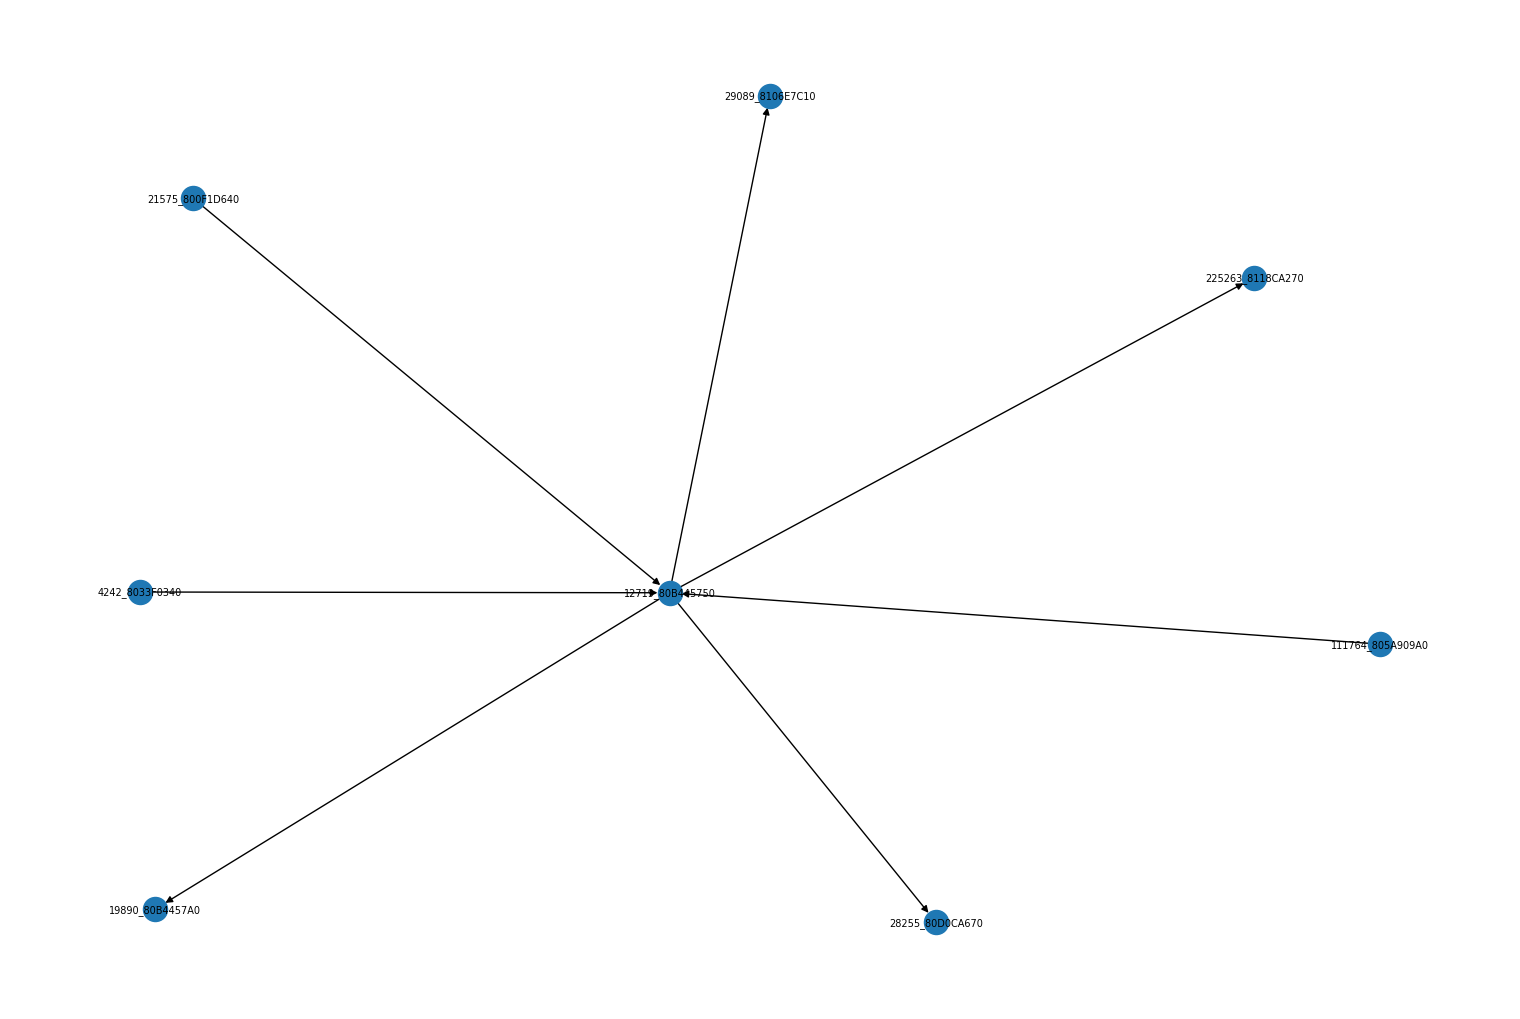

In [ ]:
# visualize graph
# there are many ways to visualize a graph, there are also other libraries and languages that specialie in graph visualization.
# pos = nx.spring_layout(G)
# fig = plt.figure(figsize=(15, 10))
# nx.draw(G, pos)
# plt.show()


demo_nodes = {example_node} | set(G.successors(example_node)) | set(G.predecessors(example_node))
demo_graph = G.subgraph(demo_nodes)
print(f"Drawing a {demo_graph.number_of_nodes()}-node neighborhood around {example_node}")

pos = nx.spring_layout(demo_graph)
fig = plt.figure(figsize=(15, 10))
nx.draw(demo_graph, pos, with_labels=True, font_size=7)
plt.show()


You can see nodes with arrows pointing to other nodes indicate that this is a directed graph and the arrows show how nodes (users) sent money to other users via transactions (edges) creating a connection.

# Exploratory Data Analysis

## Network size

Nodes: 64,067

Edges: 82,238



In-degree — how many different accounts sent money to this account

Out-degree — how many different accounts this account sent money to.

In [ ]:

print(f"Average out-degree: {sum(dict(G.out_degree()).values()) / G.number_of_nodes():.2f}")

Average out-degree: 1.28


82,238 / 64,067 = 1.28 is the mean out-degree, but it is a poor summary: the median account sends to 0 others, and two hub accounts account for 28% of all relationships.

## Degree Pattern

In [ ]:
in_deg = dict(G.in_degree())
out_deg = dict(G.out_degree())

degree_df = pd.DataFrame({
'node': list(G.nodes()),
'in_degree': [G.in_degree(n) for n in G.nodes()],
'out_degree': [G.out_degree(n) for n in G.nodes()]
})

print(degree_df.describe(), "\n")

print("Top influencers: \n", degree_df.nlargest(5, 'in_degree'), "\n")
print("Top broadcasters: \n", degree_df.nlargest(5, 'out_degree'))

          in_degree    out_degree
count  64067.000000  64067.000000
mean       1.283625      1.283625
std        3.362247     68.427166
min        0.000000      0.000000
25%        1.000000      0.000000
50%        1.000000      0.000000
75%        2.000000      1.000000
max      545.000000  14230.000000 

Top influencers: 
                   node  in_degree  out_degree
33255     70_100428660        545       14230
33260     70_1004286A8        328        8846
382     2915_801AF5660         82           0
3969   39678_80F523260         82           0
5786   40836_80F47A310         79           0 

Top broadcasters: 
                node  in_degree  out_degree
33255  70_100428660        545       14230
33260  70_1004286A8        328        8846
35516  70_100428978         75        1776
33456  70_1004286F0         55        1575
4416   70_1004289C0         68        1432


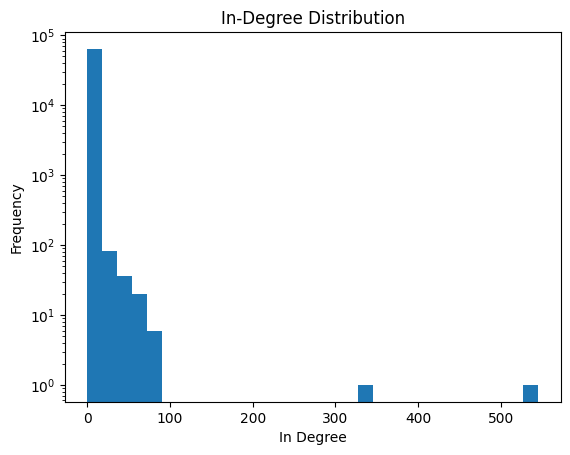

In [ ]:
in_degs = [d for n, d in G.in_degree()]

plt.hist(in_degs, bins=30, log=True)
plt.xlabel("In Degree")
plt.ylabel("Frequency")
plt.title("In-Degree Distribution")
plt.show()

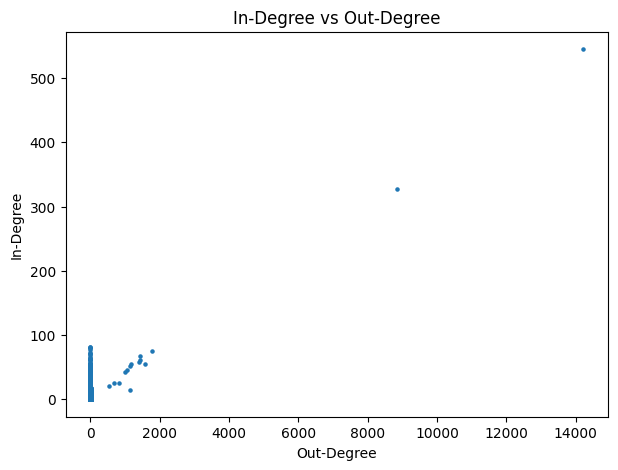

In [ ]:
plt.figure(figsize=(7,5))
plt.scatter( degree_df['out_degree'], degree_df['in_degree'], s=5)

plt.xlabel("Out-Degree")
plt.ylabel("In-Degree")
plt.title("In-Degree vs Out-Degree")
plt.show()

## Connectedness

Weakly connected: False
Strongly connected: False
Weak components: 147
Strong components: 63269
Largest weak component size: 62459


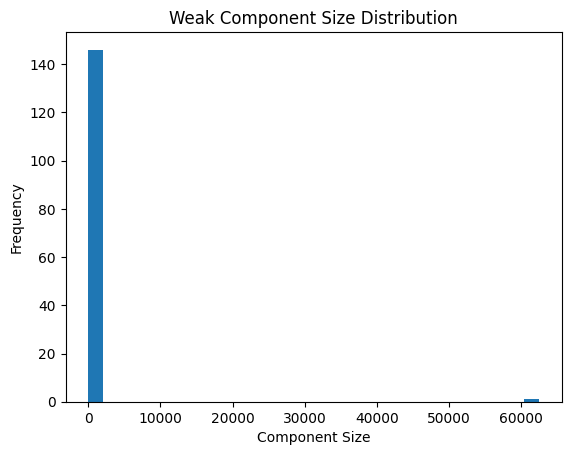

In [ ]:
print("Weakly connected:", nx.is_weakly_connected(G))
print("Strongly connected:", nx.is_strongly_connected(G))

weak_components = list(nx.weakly_connected_components(G))
strong_components = list(nx.strongly_connected_components(G))
print("Weak components:", len(weak_components))
print("Strong components:", len(strong_components))

largest_weak = max(weak_components, key=len)
print("Largest weak component size:",
len(largest_weak))

weak_sizes = [len(c) for c in nx.weakly_connected_components(G)]

plt.hist(weak_sizes, bins=30)
plt.xlabel("Component Size")
plt.ylabel("Frequency")
plt.title("Weak Component Size Distribution")
plt.show()

In [ ]:
print(f"Reciprocity: {nx.reciprocity(G):.3f}")

Reciprocity: 0.015


### Connectedness Analysis
- **Network Size:** 64,067 nodes and 82,238 edges.
- **Weakly Connected:** ❌ No. The network is divided into **147 disconnected groups**.
- **Largest Weak Component:** 62,459 nodes (**97.5% of all nodes**) belong to a single giant component, indicating that most nodes are part of one main network.
- **Strongly Connected:** ❌ No. Nodes generally cannot reach each other through directed paths in both directions.
- **Strong Components:** 63,269 strongly connected components, nearly equal to the total number of nodes, meaning almost no directed cycles: money rarely returns to where it came from.
- **Implication:** Most relationships are **one-way (directional)** rather than reciprocal: only 1.5% of relationships (reciprocity = 0.015) have a matching transaction in the opposite direction.
- **Overall Insight:** The network is dominated by a large connected structure but exhibits **low mutual reachability and high directional fragmentation**, suggesting limited bidirectional interaction among nodes.



# Mapping Laundering Attributes
Accounts appearing as either the sender or receiver of at least one laundering transaction were labeled as laundering seed nodes (is_laundering_seed = 1). Accounts added through the one-hop network expansion but not directly involved in a known laundering transaction were assigned is_laundering_seed = 0. This resulted in 6,357 seed accounts and 57,710 neighboring accounts. At the edge level, 4,929 unique sender–receiver relationships were labeled as containing at least one laundering transaction. Because transactions were aggregated by sender–receiver pair before graph construction, the number of laundering-labeled edges is lower than the number of individual laundering transactions.

In [ ]:
# Mark whether each node is directly involved
# in at least one laundering transaction

for node in G.nodes:
    G.nodes[node]["is_laundering_seed"] = int(
        node in seed_nodes
    )

In [ ]:
node_labels = nx.get_node_attributes(
    G,
    "is_laundering_seed"
)

pd.Series(node_labels).value_counts()

,count
0,57710
1,6357


0: one-hop neighbors; not directly involved in a labeled laundering transaction

1: directly involved in at least one laundering transaction

Suspicious Transactions / Relationships

In [ ]:
laundering_count = sum(node_labels.values())
n_laund_edges = sum(data["is_laundering"] for _, _, data in G.edges(data=True))

print(f"Laundering nodes: {laundering_count:,} ({laundering_count/G.number_of_nodes():.1%})")
print(f"Laundering edges: {n_laund_edges:,} ({n_laund_edges/G.number_of_edges():.2%})")

deg_by_suspicious = pd.DataFrame({
    "laundering": node_labels,
    "in_degree": in_deg,
    "out_degree": out_deg,
})
deg_by_suspicious["degree"] = deg_by_suspicious["in_degree"] + deg_by_suspicious["out_degree"]
deg_by_suspicious.groupby("laundering")[["in_degree", "out_degree", "degree"]].median()

assortativity = nx.attribute_assortativity_coefficient(G, "is_laundering_seed")
print(f"Assortativity (is_laundering_seed): {assortativity:.3f}")

Laundering nodes: 6,357 (9.9%)
Laundering edges: 4,929 (5.99%)
Assortativity (is_laundering_seed): -0.325


Assortativity is negative (−0.325): edges between a seed and a non-seed are more common than random mixing would give. This is partly built into the design, since non-seed accounts are in the network only because they touch a seed and make up 90% of nodes, so it should not be read as evidence that suspicious accounts avoid each other.

In [ ]:
print(
    "Seed accounts expected:",
    len(seed_nodes)
)

print(
    "Seed accounts marked in graph:",
    sum(node_labels.values())
)

Seed accounts expected: 6357
Seed accounts marked in graph: 6357


count how many edges in NetworkX graph are labeled as laundering

In [ ]:
n_laundering_edges = sum(
    data["is_laundering"]
    for _, _, data in G.edges(data=True) # ignores the source and target attributes; only the "is_laundering" is needed
)

print(
    "Laundering-labeled edges:",
    n_laundering_edges
)

Laundering-labeled edges: 4929


In [ ]:
# Sanity Check

# Verify the graph edge count against your edge table
print(
    "Expected laundering-labeled edges:",
    int(sub_edge_df["is_laundering"].sum())
)

print(
    "Laundering-labeled edges in graph:",
    n_laundering_edges
)

Expected laundering-labeled edges: 4929
Laundering-labeled edges in graph: 4929


In [ ]:
# Verify that laundering edges connect seed accounts
# For every edge labeled as laundering, are both the sender and receiver also correctly marked as laundering seed accounts?

bad_laundering_edges = [
    (u, v)
    for u, v, data in G.edges(data=True)
    if data["is_laundering"] == 1
    and (
        G.nodes[u]["is_laundering_seed"] != 1
        or
        G.nodes[v]["is_laundering_seed"] != 1
    )
]

print(
    "Laundering edges with incorrectly mapped nodes:",
    len(bad_laundering_edges)
)

Laundering edges with incorrectly mapped nodes: 0


In [ ]:
# Do laundering edges differ from normal edges in size or frequency?
sub_edge_df.groupby("is_laundering")[["n_tx", "total_amount", "weight"]].agg(["median", "mean"]).round(3)

n_tx        total_amount               weight       
              median   mean       median          mean median   mean
is_laundering                                                       
0                6.0  9.236      16508.6  2.505392e+07   0.00  0.224
1                1.0  3.294      10828.9  3.938518e+07   0.15  0.420

Laundering-labeled relationships are much less repeated than normal ones: the median is 1 transaction versus 6 (mean 3.3 versus 9.2). Their typical amount is somewhat lower (median 10,829 versus 16,509), but the mean is higher (3.94e7 versus 2.51e7), so a small number of very large laundering relationships pull the average up. Laundering relationships also carry a larger share of the sender's total outgoing money (median weight 0.15 versus about 0). The near-zero normal median likely reflects the two hub senders, whose money is spread across thousands of tiny relationships.

In [ ]:
# Payment-format mix: % of normal vs laundering transactions
fmt = (pd.crosstab(data_df["payment_format"], data_df["is_laundering"], normalize="columns") * 100).round(1)
fmt.columns = ["% of normal transactions", "% of laundering transactions"]
fmt.sort_values("% of laundering transactions", ascending=False)

,% of normal transactions,% of laundering transactions
payment_format,,
ACH,11.7,86.6
Cheque,41.5,6.3
Credit Card,29.4,4.0
Cash,10.9,2.1
Bitcoin,2.7,1.1
Wire,3.8,0.0


This table covers all transactions in the dataset after self-loops were removed, not only the laundering-centered subgraph. Laundering transactions are heavily concentrated in ACH (86.6% versus 11.7% of normal transactions), while cheque (6.3% versus 41.5%), credit card (4.0% versus 29.4%), cash (2.1% versus 10.9%) and wire (0.0% versus 3.8%) are underrepresented. Reinvestment does not appear because those transactions were almost all self-loops, which were removed earlier. This shows how laundering transactions differ in mix, not that ACH is a reliable indicator: from these shares, fewer than 1% of ACH transactions are laundering-labeled.

## One-Hop Transaction Network Around a Laundering Seed Account

The figure shows the immediate transaction neighborhood of a selected laundering seed account.
Nodes represent bank-account combinations, while directed edges represent aggregated
sender–receiver transaction relationships.

- **Red nodes** represent laundering seed accounts — accounts that appear as either the sender
  or receiver in at least one laundering-labeled transaction.
- **Blue nodes** represent neighboring accounts included through the one-hop expansion but not
  directly involved in a laundering-labeled transaction.
- **Red edges** represent sender–receiver relationships containing at least one laundering-labeled
  transaction.
- **Gray edges** represent relationships with no laundering-labeled transactions.

The visualization illustrates how laundering-related accounts can be examined together with their
immediate transactional context. In this example, the selected local network contains both
laundering-related and non-laundering relationships, allowing the surrounding connections of the
seed accounts to be inspected. The presence of a node or connection in this neighborhood does not,
by itself, indicate money laundering.

Visualizing 6 nodes and 6 edges


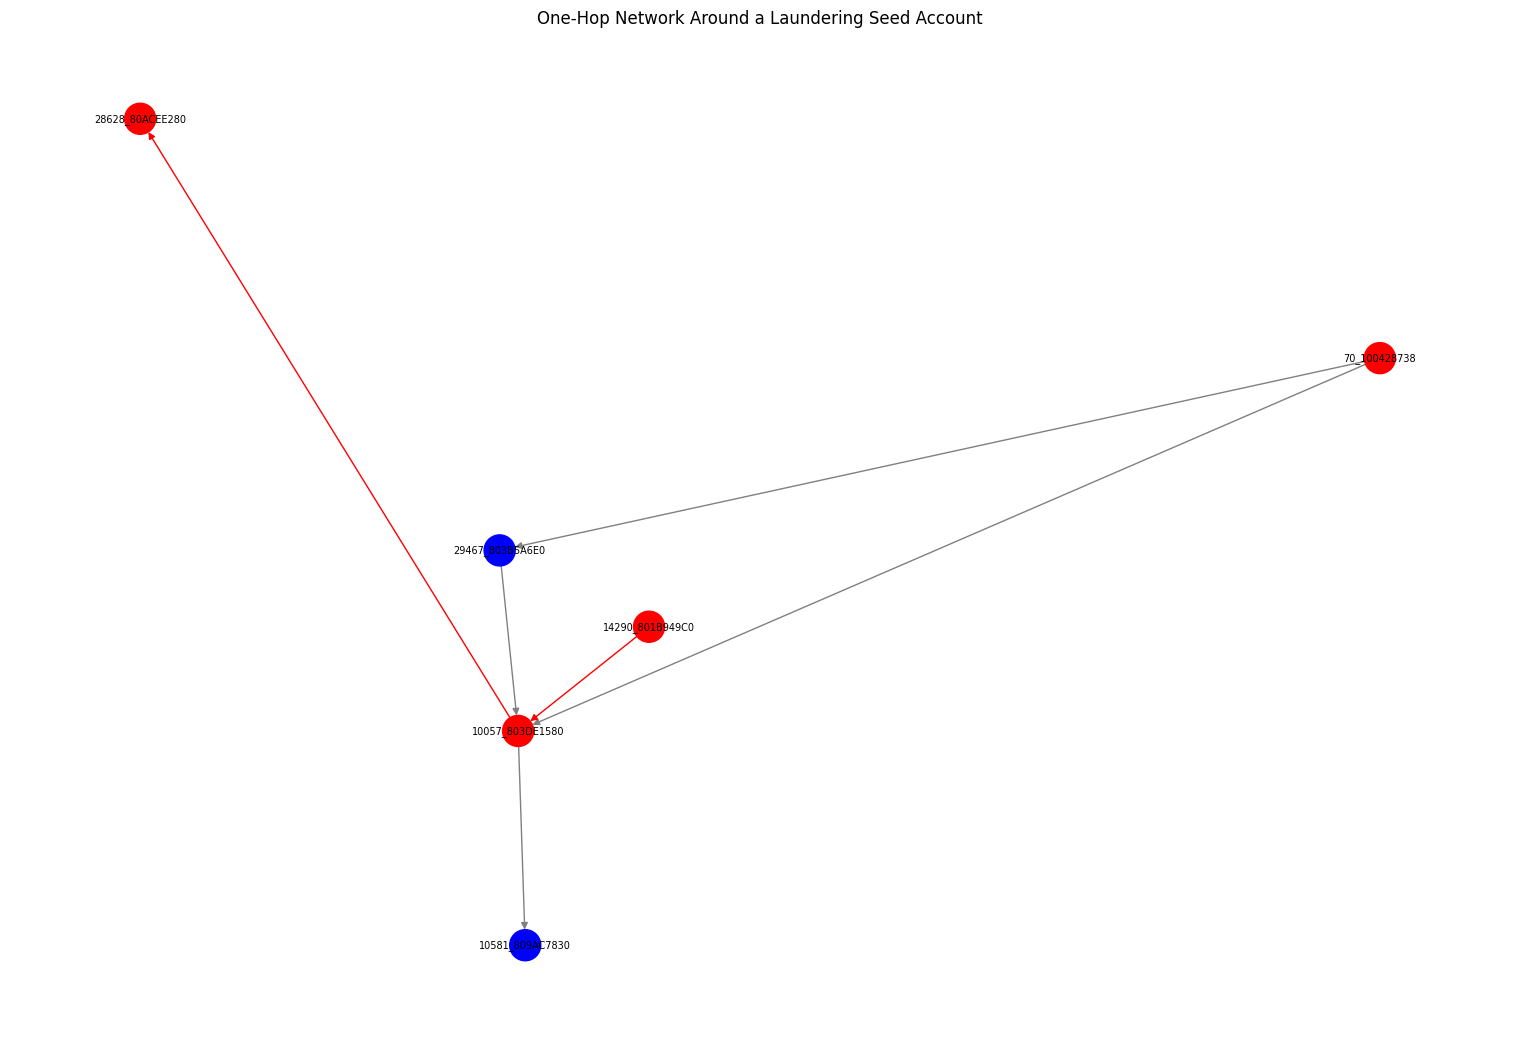

In [ ]:
# Select one laundering-seed account
example_seed = next(
    node
    for node in G.nodes()
    if G.nodes[node]["is_laundering_seed"] == 1
)

# Get its immediate incoming and outgoing neighbors
demo_nodes = (
    {example_seed}
    | set(G.predecessors(example_seed))
    | set(G.successors(example_seed))
)

# Create a smaller graph for visualization
demo_graph = G.subgraph(demo_nodes).copy()

print(
    f"Visualizing {demo_graph.number_of_nodes()} nodes "
    f"and {demo_graph.number_of_edges()} edges"
)

# Determine node positions
pos = nx.spring_layout(
    demo_graph,
    seed=42
)

# Node colors based on laundering-seed status
node_colors = [
    'red'
    if demo_graph.nodes[node]["is_laundering_seed"] == 1
    else 'blue'
    for node in demo_graph.nodes()
]

# Edge colors based on laundering status
edge_colors = [
    'red'
    if data["is_laundering"] == 1
    else 'gray'
    for _, _, data in demo_graph.edges(data=True)
]

# Draw graph
plt.figure(figsize=(15, 10))

nx.draw(
    demo_graph,
    pos,
    node_color=node_colors,
    edge_color=edge_colors,
    with_labels=True,
    node_size=500,
    font_size=7,
    arrows=True
)

plt.title("One-Hop Network Around a Laundering Seed Account")

plt.show()

# Neighborhood Measures

## Neighborhood Metrics

**Degree** - How connected? The number of distinct accounts it has transacted with.

**In-degree / Out-degree** - How many distinct accounts sent money to it / received money from it. Fan-in and fan-out are classic layering signals.

**Triangles** - Do this account's counterparties also transact with each other?

**Clustering** - What share of the account's possible counterparty pairs actually transact?

**Ego Density** - How interconnected is the account's whole local neighborhood, at once?

**Relational Neighbor** - Are this account's counterparties already known to be suspicious?

**Method.** Seeds (accounts on either side of a laundering transaction) are compared with a comparison group on a balanced sample. All metrics are computed on a graph **without the laundering edges**, because a seed is a seed because of those edges. Keeping them would leak the label into degree, triangles and the rest.

In [ ]:
RANDOM_STATE, N_PER_CLASS, TEST_SIZE, N_BOOT = 42, 2_000, 0.30, 300
COMPARISON = "neighbors"
FEATURES = ["degree", "in_degree", "out_degree", "triangles", "clustering", "ego_density", "rn_frac"]

### Clean Graph for Neighborhood Metrics

In [ ]:
clean_edges = edge_df[edge_df["is_laundering"] == 0]
G_clean = nx.from_pandas_edgelist(clean_edges, "source", "target")   # undirected
G_clean.add_nodes_from(edge_df["source"])
G_clean.add_nodes_from(edge_df["target"])

clean_out = clean_edges.groupby("source")["target"].nunique()
clean_in = clean_edges.groupby("target")["source"].nunique()

print(f"G_clean: {G_clean.number_of_nodes():,} nodes, {G_clean.number_of_edges():,} edges")

G_clean: 422,734 nodes, 639,532 edges


### Balanced Sample
We draw 2,000 seeds and 2,000 non-seed neighbors and split them 70/30 into train and test. Only 5% of the one-hop neighborhood is seeds, so a balanced sample keeps the comparison fair and keeps AUC easy to read.

In [ ]:
def draw_sample(comparison):
    rng = np.random.default_rng(RANDOM_STATE)
    pos_pool = sorted(seed_nodes)
    neg_pool = sorted((set(sub_nodes) if comparison == "neighbors" else set(G_clean)) - seed_nodes)
    n = min(N_PER_CLASS, len(pos_pool), len(neg_pool))
    df = pd.DataFrame({"node": rng.choice(pos_pool, n, replace=False).tolist()
                             + rng.choice(neg_pool, n, replace=False).tolist()})
    df["suspicious"] = df["node"].isin(seed_nodes).astype(int)
    df["split"] = "train"
    _, test_idx = train_test_split(df.index, test_size=TEST_SIZE,
                                   stratify=df["suspicious"], random_state=RANDOM_STATE)
    df.loc[test_idx, "split"] = "test"
    return df

### Computing the Neighborhood Features

For every sampled account we compute degree, in-degree and out-degree, triangles, clustering and ego density on `G_clean`. Clustering is undefined for accounts with fewer than 2 counterparties, and ego density is undefined for accounts with none, so those values are left missing. The relational neighbor is the share of an account's counterparties that are known seeds, with the labels of test accounts hidden.

In [ ]:
def compute_features(sample):
    nodes = sample["node"].tolist()
    test_nodes = set(sample.loc[sample["split"] == "test", "node"])
    m = sample.set_index("node").copy()

    m["degree"] = pd.Series(dict(G_clean.degree(nodes)))
    m["in_degree"] = clean_in.reindex(m.index).fillna(0)
    m["out_degree"] = clean_out.reindex(m.index).fillna(0)
    m["triangles"] = pd.Series(nx.triangles(G_clean, nodes))
    m["clustering"] = pd.Series(nx.clustering(G_clean, nodes)).where(m["degree"] >= 2)
    m["ego_density"] = pd.Series(
        [nx.density(G_clean.subgraph(set(G_clean[v]) | {v})) for v in m.index], index=m.index
    ).where(m["degree"] >= 1)

    def rel_neighbor(v):
        known = [u for u in G_clean[v] if u not in test_nodes]
        return np.mean([u in seed_nodes for u in known]) if known else np.nan
    m["rn_frac"] = [rel_neighbor(v) for v in m.index]
    return m

### Seeds vs Neighbors: Summary Statistics

In [ ]:
m = compute_features(draw_sample(COMPARISON))
print(m.groupby(["split", "suspicious"]).size().unstack(), "\n")

comp, seed = m[m["suspicious"] == 0], m[m["suspicious"] == 1]
test = m[m["split"] == "test"]

summary = pd.DataFrame({
    "comp Q1": comp[FEATURES].quantile(.25), "comp median": comp[FEATURES].median(), "comp Q3": comp[FEATURES].quantile(.75),
    "seed Q1": seed[FEATURES].quantile(.25), "seed median": seed[FEATURES].median(), "seed Q3": seed[FEATURES].quantile(.75),
    "test AUC": pd.Series({f: roc_auc_score(test.loc[test[f].notna(), "suspicious"], test[f].dropna()) for f in FEATURES}),
    "share defined (test)": test[FEATURES].notna().mean(),
})
summary.round(3)

suspicious     0     1
split                 
test         600   600
train       1400  1400 



,comp Q1,comp median,comp Q3,seed Q1,seed median,seed Q3,test AUC,share defined (test)
degree,2.000,3.00,5.000,1.0,3.0,4.000,0.397,1.000
in_degree,1.000,2.00,3.000,1.0,2.0,2.000,0.421,1.000
out_degree,0.000,1.00,3.000,0.0,1.0,2.000,0.414,1.000
triangles,0.000,0.00,0.000,0.0,0.0,0.000,0.459,1.000
clustering,0.000,0.00,0.000,0.0,0.0,0.000,0.466,0.783
ego_density,0.333,0.50,0.667,0.4,0.5,0.667,0.540,0.937
rn_frac,0.111,0.25,0.500,0.0,0.0,0.000,0.151,0.921


**Neighborhood metrics for seeds and non-seed neighbors.** Each row shows the quartiles for the comparison group and for seeds. `test AUC` is measured on the held-out 600 + 600 accounts: above 0.5 means seeds score higher, below 0.5 means lower. `share defined` is the fraction of test accounts where the metric exists.

**Interpretation.** Seeds and neighbors look much alike. Degree, in-degree and out-degree have the same medians (3, 2 and 1) in both groups, and seeds have a slightly lower upper tail (AUC about 0.40, or about 0.60 when flipped). Triangles and clustering are 0 for at least three quarters of accounts in both groups. Ego density is nearly identical (median 0.5, AUC 0.54). The relational neighbor is the one large gap (AUC 0.15), but it comes from how the samples were built rather than from account behavior (see the model section).

### Distributions

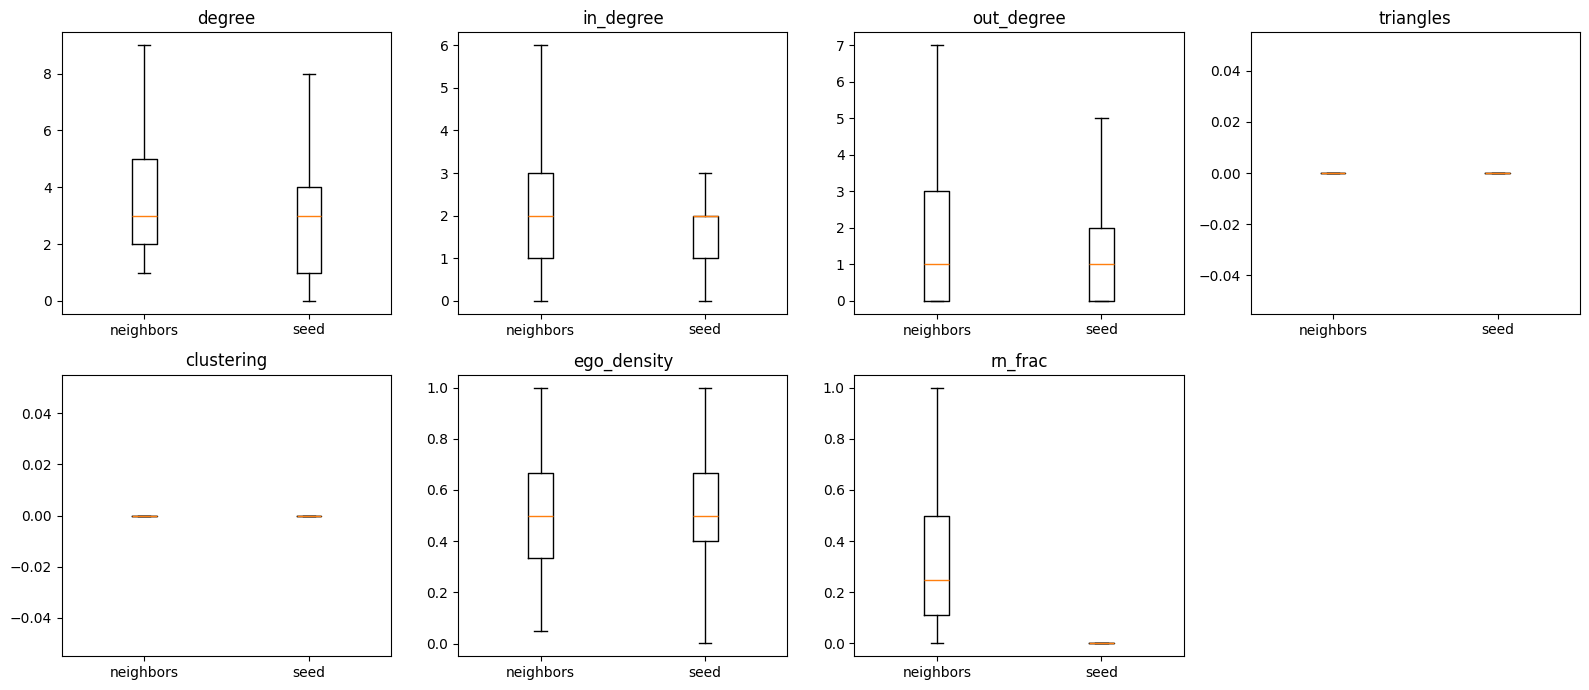

In [ ]:
fig, axes = plt.subplots(2, 4, figsize=(16, 7))
for ax, col in zip(axes.ravel(), FEATURES):
    ax.boxplot([m.loc[m["suspicious"] == c, col].dropna() for c in (0, 1)], showfliers=False)
    ax.set_xticklabels([COMPARISON, "seed"])
    ax.set_title(col)
axes.ravel()[-1].axis("off")
plt.tight_layout()
plt.show()

* **Degree** - Seeds and their non-seed neighbors have the same median degree (3 distinct counterparties), but seeds sit slightly lower: the middle half is roughly 1-4 for seeds versus 2-5 for neighbors. The effect is weak  In-degree and out-degree show the same pattern, with equal medians and a lower upper tail for seeds. Part of the gap is mechanical: neighbors are included because they touch a seed, so they always have at least one edge, while seeds lost their laundering edges, so 29% have fewer than 2 counterparties versus 12% of neighbors.
* **Triangles** - Both groups sit at 0 (at least three quarters of accounts in each have no triangle). Triangles are rare in this sparse graph, so this metric does not separate the groups (AUC 0.46).
* **Clustering** - Defined only for accounts with at least 2 counterparties (78% of test accounts). Both groups have a median of 0 and clustering is low everywhere (below 0.16 in every degree bin). Within degree bins, seeds have lower clustering only at degrees 2-3 (0.07 vs 0.16, and 0.05 vs 0.08). The gap disappears at degrees 4-5 and reverses slightly at 6 and above. So both groups have mostly star-shaped neighborhoods, and the overall difference is largely a degree effect.
* **Ego density** - Medians are the same (0.5), and the middle halves overlap almost completely (AUC 0.54, negligible). This is not independent evidence: ego density is determined by degree and clustering, and an account with a single counterparty has density 1 automatically. It restates the degree and clustering results.
* **Relational neighbor** - Seeds are at 0 and neighbors are well above it (AUC 0.15), but this comes from how the samples were built. Neighbors are in the sample because they touch a seed, while the laundering-flagged pairs between seeds were removed on purpose, so almost none of a seed's remaining counterparties are known seeds. This does not show that suspicious accounts avoid each other. For the same reason, the combined model's high AUC (0.874) is driven by this feature and by missing-value indicators, and should not be read as evidence that neighborhood structure detects laundering.

In [ ]:
deg2 = m[m["degree"] >= 2].copy()
deg2["degree_bin"] = pd.cut(deg2["degree"], [1, 2, 3, 5, 10, np.inf], labels=["2", "3", "4-5", "6-10", "11+"])
deg2.pivot_table(index="degree_bin", columns="suspicious", values="clustering",
                 aggfunc=["mean", "count"], observed=True).round(3)

mean        count     
suspicious      0      1     0    1
degree_bin                         
2           0.156  0.070   417  400
3           0.077  0.049   393  320
4-5         0.046  0.043   457  388
6-10        0.019  0.028   387  232
11+         0.014  0.028    97   76

## Clustering
Accounts with more counterparties need many more links among them to reach a high clustering value. To separate the two, we compare mean clustering within degree bins.

In [ ]:
X = m[FEATURES].copy()
X[["degree", "in_degree", "out_degree", "triangles"]] = np.log1p(X[["degree", "in_degree", "out_degree", "triangles"]])
X["clustering_missing"] = X["clustering"].isna().astype(int)
X["rn_missing"] = X["rn_frac"].isna().astype(int)
X = X.fillna(0)

tr, te = m["split"] == "train", m["split"] == "test"
clf = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000)).fit(X[tr], m.loc[tr, "suspicious"])
print(f"Logistic regression, test AUC: {roc_auc_score(m.loc[te, 'suspicious'], clf.predict_proba(X[te])[:, 1]):.3f}")
pd.Series(clf[-1].coef_[0], index=X.columns).sort_values(key=abs, ascending=False).round(3)

Logistic regression, test AUC: 0.874


,0
rn_frac,-2.114
clustering_missing,2.005
rn_missing,-1.772
ego_density,-0.745
degree,-0.586
out_degree,-0.521
in_degree,-0.454
triangles,0.237
clustering,0.012


# Measures of Centrality
- A node's degree is the sum of its edges. the highly connected a node is, indicate a node's importance and a network's centrality. A node with large number of edges (or high degree) are known as hubs.
- Who are the important people, or hubs (nodes with large # of connections), in the network?

In [ ]:
# Given a node it will count how many edges are connected to it
G.degree('1467_802764130')

3

In [ ]:
# Let's generate all node degree values and assign them as an attribute
degree_dict = dict(G.degree(G.nodes()))
nx.set_node_attributes(G, degree_dict, 'degree')
print(G.nodes['1467_802764130'])

degree_dict = dict(G.degree(G.nodes()))
nx.set_node_attributes(G, degree_dict, 'degree')
print(G.nodes[example_node])

{'is_laundering_seed': 1, 'degree': 3}
{'is_laundering_seed': 1, 'degree': 7}


In [ ]:
# What nodes have a value of more than 5 degrees
sorted(list(filter(lambda x: x[1]['degree']>5, G.nodes(data=True))), key=lambda x:x[1]['degree'], reverse=True)

[('70_100428660', {'is_laundering_seed': 1, 'degree': 14775}),
 ('70_1004286A8', {'is_laundering_seed': 1, 'degree': 9174}),
 ('70_100428978', {'is_laundering_seed': 1, 'degree': 1851}),
 ('70_1004286F0', {'is_laundering_seed': 1, 'degree': 1630}),
 ('70_1004289C0', {'is_laundering_seed': 1, 'degree': 1500}),
 ('70_100428780', {'is_laundering_seed': 1, 'degree': 1482}),
 ('70_100428810', {'is_laundering_seed': 1, 'degree': 1452}),
 ('70_1004287C8', {'is_laundering_seed': 1, 'degree': 1237}),
 ('70_100428738', {'is_laundering_seed': 1, 'degree': 1187}),
 ('70_100428A51', {'is_laundering_seed': 1, 'degree': 1161}),
 ('70_1004288A0', {'is_laundering_seed': 1, 'degree': 1101}),
 ('70_100428858', {'is_laundering_seed': 1, 'degree': 1031}),
 ('70_1004288E8', {'is_laundering_seed': 1, 'degree': 851}),
 ('70_100428A08', {'is_laundering_seed': 1, 'degree': 722}),
 ('70_100428930', {'is_laundering_seed': 1, 'degree': 567}),
 ('2915_801AF5660', {'is_laundering_seed': 1, 'degree': 82}),
 ('39678_8

**Degree Centrality** <br>
Degree Centrality measures how well-connected a node is.

In [ ]:
deg_cent = nx.degree_centrality(G)

deg_df = pd.DataFrame(
    deg_cent.items(),
    columns=['node', 'degree_centrality']
)

deg_df.describe()

,degree_centrality
count,64067.000000
mean,0.000040
std,0.001109
min,0.000016
25%,0.000016
50%,0.000016
75%,0.000031
max,0.230622


**In-Degree Centrality** <br>
In-Degree Centrality measures how many incoming ties a node receives.

In [ ]:
in_cent = nx.in_degree_centrality(G)

in_df = pd.DataFrame(
    in_cent.items(),
    columns=['node', 'in_degree_centrality']
)

in_df.sort_values("in_degree_centrality", ascending=False).head(10)

,node,in_degree_centrality
33255,70_100428660,0.008507
33260,70_1004286A8,0.005120
3969,39678_80F523260,0.001280
382,2915_801AF5660,0.001280
9637,14_8007BC070,0.001233
5786,40836_80F47A310,0.001233
9638,14_8007C2A40,0.001202
35516,70_100428978,0.001171
6031,137897_8147F3F50,0.001124
6032,1547_81484C700,0.001124


**Out-Degree Centrality** <br>
Out-Degree Centrality measures the extent to which a node initiates interactions.

In [ ]:
out_cent = nx.out_degree_centrality(G)

out_df = pd.DataFrame(
    out_cent.items(),
    columns=['node','out_degree_centrality']
)

out_df.sort_values("out_degree_centrality", ascending=False).head(10)

,node,out_degree_centrality
33255,70_100428660,0.222115
33260,70_1004286A8,0.138076
35516,70_100428978,0.027721
33456,70_1004286F0,0.024584
4416,70_1004289C0,0.022352
19779,70_100428780,0.022180
34272,70_100428810,0.021759
33959,70_1004287C8,0.018450
36357,70_100428A51,0.017903
33237,70_100428738,0.017732


**Betweenness Centrality** <br>
Betweenness centrality looks at the shortest paths, good for identifying key nodes serves as connection between clusters. While a node with a high no. of degrees is a hub, a node that is the shortest path between two clusters is called a broker. They act as a "bridge" between two (or more) communities/clusters.

NOTE: Some nodes will have high centrality, but low degrees - which means they are important brokers but are not hubs.

In [ ]:
# function to compute for betweenness
# Approximate from a random sample of k source nodes instead.
bet_cent = nx.betweenness_centrality(G, k=1000, seed=280)

bet_df = pd.DataFrame(bet_cent.items(), columns=['node','bet_degree_centrality'])
bet_df.sort_values("bet_degree_centrality", ascending=False).head(10)

,node,bet_degree_centrality
33255,70_100428660,0.004011
33260,70_1004286A8,0.001759
21685,1_8000EEE80,0.000186
7164,11_8000631E0,0.000119
21644,1_8000F49E0,0.000090
10957,12_800063990,0.000085
15723,1490_8002BCF50,0.000081
7464,22_800241D60,0.000077
11103,1_8001BA930,0.000076
7181,23_8000FFF70,0.000073


**Closeness Centrality** <br>
Closeness measures how close a node is to all other nodes. The more central a node is, the lower its closeness value. Another way to think of this metric is its a measure of how long it will take to spread information from the current node to all other nodes.

In [ ]:
# function to compute for closeness
close_cent = nx.closeness_centrality(G)

#closeness_series = pd.Series(closeness, name="closeness").loc[list(seed_nodes)]
#closeness_series.sort_values(ascending=False).head(10)
close_df = pd.DataFrame(
    close_cent.items(),
    columns=['node','close_degree_centrality']
)

close_df.sort_values("close_degree_centrality", ascending=False).head(10)

,node,close_degree_centrality
33255,70_100428660,0.008507
16376,5394_806A65C90,0.005781
12879,13432_804EA8EB0,0.005780
28120,9482_80D430E30,0.005777
16156,2627_804FB5F60,0.005777
17095,3242_8021467E0,0.005775
28495,221527_80AD61260,0.005772
6011,7042_80B4BC6F0,0.005772
505,13145_812EDAD60,0.005772
20384,23537_80BBE0130,0.005772


**Eigenvector Centrality** <br>
Eigenvector centrality is similar to degrees but also cares about how many hubs a node is connected to. You can think of this as a person who is connected to the popular people of a network. Google's page rank is based on Eigenvector centrality of which a page's rank is determined by how many other pages point to it and how important those pages are.

In [ ]:
# This might cause an error if the function can't successfully compute the eigenvector due to a small network.
eig_cent = nx.eigenvector_centrality(G)

eig_df = pd.DataFrame(
    eig_cent.items(),
    columns=['node','eig_centrality']
)

eig_df.sort_values("eig_centrality", ascending=False).head(10)

,node,eig_centrality
6598,222_811D80C30,0.506618
6617,118_811B6E170,0.325559
6620,119_8000DB3C0,0.273241
6482,118_811A67510,0.247107
6626,228101_80B0C3F40,0.242121
6622,121_8000E1590,0.241828
6618,118_811B9B110,0.216966
6623,148016_811DCA680,0.216966
6970,223_811A65E30,0.206397
6621,119_811DCA9B0,0.166519


**PageRank** <br>
PageRank identifies important nodes considering both the quantity and quality of incoming links.

In [ ]:
pagerank = nx.pagerank(G)

pagerank_df = pd.DataFrame(
    pagerank.items(),
    columns=['node','pagerank']
)

pagerank_df.sort_values("pagerank", ascending=False).head(10)

,node,pagerank
33255,70_100428660,0.004379
33260,70_1004286A8,0.002639
9637,14_8007BC070,0.001169
9638,14_8007C2A40,0.001167
8122,5464_8147FC3C0,0.001042
7978,120193_80C2E7860,0.001016
7980,232304_80C2D6A60,0.001010
2165,110_80CFCDFB0,0.000946
2166,135104_80CFE7120,0.000944
3149,123102_80DA50520,0.000924


Graph density represents the ratio between the edges present in a graph and the maximum number of edges that the graph can contain also known as "how closely knit the network is"

In [ ]:
# function to compute for network density
nx.density(G)
print(f"Density: {nx.density(G):.2e}")

Density: 2.00e-05


# Graph Basics
Let's look at some standard metrics to review when analyzing graphs.

# Centrality versus centralization
- Centrality is a node level metric; each node has a centrality score representing it’s position within the network
- Centralization is a group level metric indicating the extent to which the network is dominated by one or a few nodes

# An Undirected Graph
An undirected graph, the edges are bidirectional with no direction associated with them.

Hence, the graph can be traversed in either direction. The absence of an arrow tells us that the graph is undirected.


# Undirected Graph Metrics


There are some metrics that only work in undirected Graphs, so let's re-create the graph to reflect this. We'll consider all connection as working both ways for this.

In [ ]:
# Let's recreate our graph as undirected for the following exercises

G_undirected = nx.from_pandas_edgelist(
    edge_df,
    edge_attr=True,
    create_using=nx.Graph(),
)

Diameter is the length of the path between the two nodes that are furthest apart. The measure is designed to give you a sense of the network’s overall size, the distance from one end of the network to another.

In [ ]:
# unfortunately this might cause an error if our network is not fully connected (there are some components that are not connected)
# nx.diameter(G_undirected)

In [ ]:
# This is a good test to see if your graph is fully connected
nx.is_connected(G_undirected)

False

# A connected graph has just one component

In [ ]:
# What components do you have?
components = nx.connected_components(G_undirected)
list(components) # these are the list of "sub networks" in your graph

[{'17861_809478350',
  '16450_804A62500',
  '29404_80897A2F0',
  '153502_813EABE01',
  '112_80F13B3A0',
  '28255_803130170',
  '126783_814694750',
  '1292_801175E60',
  '18097_8030EE820',
  '312273_80EF92010',
  '4766_8039258A0',
  '121987_808621A20',
  '12719_8101AFEE0',
  '124290_80FBE63B0',
  '39668_80EF3EAC0',
  '220_813F96FA1',
  '218755_80FBAAAF0',
  '32082_802B926F0',
  '16792_8061A26A0',
  '130449_80DC31190',
  '25075_801F1A600',
  '5329_803BAF080',
  '39279_81147FFF0',
  '1267_80EF981C0',
  '38478_80E5CBF30',
  '11318_8073E2CC0',
  '21940_8043B2590',
  '11056_8007DBC10',
  '5175_80804C230',
  '13345_80DE4AEF0',
  '21745_8018D94B0',
  '22205_8018979C0',
  '34736_80C269D80',
  '29944_80C2E6020',
  '327925_80A91AA40',
  '22_8009CB1D0',
  '44866_810A7DC70',
  '3489_8093F54D0',
  '315747_807352B30',
  '212_80879C8A0',
  '312863_804CBF420',
  '227171_80D50B430',
  '219860_80B5B33D0',
  '221868_80AB87E30',
  '134117_80CD6CA30',
  '22732_8106BE250',
  '122352_809C8E400',
  '3229_80146

In [ ]:
# what's the largest of the components?
largest_component = max(nx.connected_components(G_undirected), key=len)
print("size of largest: ",len(largest_component))
list(largest_component)

size of largest:  372089


['17861_809478350',
 '16450_804A62500',
 '29404_80897A2F0',
 '153502_813EABE01',
 '112_80F13B3A0',
 '28255_803130170',
 '126783_814694750',
 '1292_801175E60',
 '18097_8030EE820',
 '312273_80EF92010',
 '4766_8039258A0',
 '121987_808621A20',
 '12719_8101AFEE0',
 '124290_80FBE63B0',
 '39668_80EF3EAC0',
 '220_813F96FA1',
 '218755_80FBAAAF0',
 '32082_802B926F0',
 '16792_8061A26A0',
 '130449_80DC31190',
 '25075_801F1A600',
 '5329_803BAF080',
 '39279_81147FFF0',
 '1267_80EF981C0',
 '38478_80E5CBF30',
 '11318_8073E2CC0',
 '21940_8043B2590',
 '11056_8007DBC10',
 '5175_80804C230',
 '13345_80DE4AEF0',
 '21745_8018D94B0',
 '22205_8018979C0',
 '34736_80C269D80',
 '29944_80C2E6020',
 '327925_80A91AA40',
 '22_8009CB1D0',
 '44866_810A7DC70',
 '3489_8093F54D0',
 '315747_807352B30',
 '212_80879C8A0',
 '312863_804CBF420',
 '227171_80D50B430',
 '219860_80B5B33D0',
 '221868_80AB87E30',
 '134117_80CD6CA30',
 '22732_8106BE250',
 '122352_809C8E400',
 '3229_80146C950',
 '10614_806419BC0',
 '15180_80D088000',
 

In [ ]:
# what's the diameter of this component?
subgraph = G_undirected.subgraph(largest_component)
diameter = nx.approximation.diameter(subgraph)
print("Approximate network diameter of largest component (lower bound):", diameter)

Approximate network diameter of largest component (lower bound): 28


There should be no larger diameter for the other components, as this is already the largest of the components.

Triadic closure is a metric that tries to estimate that if two nodes are connected to a 3rd node, most probably these two nodes might have a 'hidden' connection. It's similar to how in life, two people can know a 3rd person thru different circumstances. #smallworld

Triadic closure is measured via transitivity which is a measure between 0 and 1. It is similar to density in which it tries to measure how connected a network is in terms of a ratio against possible connections - that there is a "likelihood" that a connection exists that currently is not captured in the graph.

In [ ]:
# if the network is not highly connected it might show a low value
triadic_closure = nx.transitivity(G_undirected)
print("Triadic closure:", triadic_closure)

Triadic closure: 0.0004894290077378683


# What is community detection?

In the study of complex networks, a network is said to have community structure if the nodes of the network can be easily grouped into (potentially overlapping) sets of nodes such that each set of nodes is densely connected internally. In the particular case of non-overlapping community finding, this implies that the network divides naturally into groups of nodes with dense connections internally and sparser connections between groups. But overlapping communities are also allowed. The more general definition is based on the principle that pairs of nodes are more likely to be connected if they are both members of the same community(ies), and less likely to be connected if they do not share communities.

# How is it different from clustering?
The difference is minor in the sense that community detection is the detection of "tightly related groups" in a network, which indicates that it only exists in a graph context. On the other hand, clusters can be seen applied in non-graph contexts where in instead of relationships, attributes/features are used to compute for "distances".

# Community detection using Greedy Modularity Maximization
Greedy modularity maximization begins with each node in its own community and joins the pair of communities that most increases modularity until no such pair exists or until number of communities n_communities is reached.

Note: There are a lot of algorithms that can be used to 'detect' communities in networks.

# What is modularity in community detection?
Modularity is a measure of the structure of networks or graphs which measures the strength of division of a network into modules (also called groups, clusters or communities). Networks with high modularity have dense connections between the nodes within modules but sparse connections between nodes in different modules.

In [ ]:
# 1. CREATE ONE UNDIRECTED ROW PER ACCOUNT PAIR

# This step converts directed sender–receiver relationships into one undirected record for each unique pair of accounts.
# Transactions in either direction between the same two accounts are combined, while preserving the total number of transactions,
# total amount transferred, number of laundering transactions, and whether the relationship contains any laundering activity.

# This is important for community detection because algorithms such as Greedy Modularity focus on how strongly accounts are connected as groups,
# rather than on the direction of individual transactions. Combining both directions prevents the same account pair from being counted as two
# separate relationships and provides a cleaner representation of the network structure.

lo = np.where(
    sub_edge_df["source"] < sub_edge_df["target"],
    sub_edge_df["source"],
    sub_edge_df["target"]
)

hi = np.where(
    sub_edge_df["source"] < sub_edge_df["target"],
    sub_edge_df["target"],
    sub_edge_df["source"]
)

# Starting from sub_edge_df, add standardized account-pair columns, group all transactions belonging to the same pair of accounts,
# then summarize their total transactions, total amount, laundering count, and whether the pair ever had laundering activity.

pair_df = (
    sub_edge_df
    .assign(
        node_a=lo,
        node_b=hi
    )
    .groupby(
        ["node_a", "node_b"],
        as_index=False
    )
    .agg(
        n_tx=("n_tx", "sum"),
        total_amount=("total_amount", "sum"),
        n_laundering=("n_laundering", "sum"),
        is_laundering=("is_laundering", "max")
    )
)

pair_df.head()

,node_a,node_b,n_tx,total_amount,n_laundering,is_laundering
0,10057_803AACE20,24_803A7B250,2,39603653.06,0,0
1,10057_803AACE20,70_100428738,14,282131.29,0,0
2,10057_803AB4F70,70_100428738,2,785980.09,0,0
3,10057_803AB6EC0,210690_80B19A9F0,2,30478.28,0,0
4,10057_803AB6EC0,70_100428738,2,362793.73,0,0


In [ ]:
# 2. BUILD UNDIRECTED GRAPH

G_undirected_full = nx.from_pandas_edgelist(
    pair_df,
    source="node_a",
    target="node_b",
    edge_attr=[
        "n_tx",
        "total_amount",
        "n_laundering",
        "is_laundering"
    ],
    create_using=nx.Graph()
)

print(
    f"Full undirected graph: "
    f"{G_undirected_full.number_of_nodes():,} nodes, "
    f"{G_undirected_full.number_of_edges():,} edges"
)

Full undirected graph: 64,067 nodes, 81,611 edges


In [ ]:
# 3. CREATE LAUNDERING-ONLY NETWORK

laundering_pairs = pair_df[
    pair_df["is_laundering"] == 1
].copy()

G_laundering = nx.from_pandas_edgelist(
    laundering_pairs,
    source="node_a",
    target="node_b",
    create_using=nx.Graph()
)

print(
    f"Laundering-only graph: "
    f"{G_laundering.number_of_nodes():,} nodes, "
    f"{G_laundering.number_of_edges():,} edges"
)

Laundering-only graph: 6,357 nodes, 4,889 edges


In [ ]:
# 4. IDENTIFY LAUNDERING SEED ACCOUNTS

seed_nodes = (
    set(laundering_pairs["node_a"])
    |
    set(laundering_pairs["node_b"])
)

print(
    "Laundering seed accounts:",
    len(seed_nodes)
)

Laundering seed accounts: 6357


In [ ]:
# 5. FIND CONNECTED LAUNDERING COMPONENTS

# A component is simply a group of nodes that are connected to each other, but not connected to nodes in another group.
# Find all separate connected groups of laundering-related accounts, then arrange those groups from the largest to the smallest.

laundering_components = sorted(
    nx.connected_components(G_laundering),
    key=len,
    reverse=True
)

print(
    "Number of laundering components:",
    len(laundering_components)
)

print("\nLargest laundering components:")

for idx, component in enumerate(
    laundering_components[:10],
    start=1
):
    print(
        f"Component {idx}: "
        f"{len(component)} laundering-related accounts"
    )

Number of laundering components: 1843

Largest laundering components:
Component 1: 241 laundering-related accounts
Component 2: 200 laundering-related accounts
Component 3: 190 laundering-related accounts
Component 4: 50 laundering-related accounts
Component 5: 43 laundering-related accounts
Component 6: 42 laundering-related accounts
Component 7: 39 laundering-related accounts
Component 8: 35 laundering-related accounts
Component 9: 30 laundering-related accounts
Component 10: 30 laundering-related accounts


In [ ]:
# 6. ONE-HOP EXPANSION

# This function expands the selected core group by adding all accounts that are directly connected to any account in the core.
# In other words, it keeps the laundering-related accounts and includes their immediate transaction neighbors.

# This is important because community detection should not examine laundering accounts in isolation. Adding one-hop neighbors preserves the
# surrounding transaction context and helps reveal how laundering-related accounts are connected to nearby non-seed accounts.

def expand_one_hop(G, core_nodes):

    expanded_nodes = set(core_nodes)

    for node in core_nodes:

        if node in G:
            expanded_nodes.update(
                G.neighbors(node)
            )

    return expanded_nodes

In [ ]:
# 7. SELECT MANAGEABLE LAUNDERING-CENTERED NETWORK

MIN_NODES = 30
MAX_NODES = 300

candidate_components = []

for rank, component in enumerate(
    laundering_components,
    start=1
):

    expanded = expand_one_hop(
        G_undirected_full,
        component
    )

    n_expanded = len(expanded)

    if MIN_NODES <= n_expanded <= MAX_NODES:

        candidate_components.append({
            "rank": rank,
            "core_nodes": set(component),
            "expanded_nodes": expanded,
            "core_size": len(component),
            "expanded_size": n_expanded
        })

print(
    "Eligible components:",
    len(candidate_components)
)

Eligible components: 164


In [ ]:
selected = max(
    candidate_components,
    key=lambda x: x["expanded_size"]
)

print(
    "Selected laundering component:",
    selected["rank"]
)

print(
    "Laundering core:",
    selected["core_size"],
    "accounts"
)

print(
    "After one-hop expansion:",
    selected["expanded_size"],
    "accounts"
)

Selected laundering component: 7
Laundering core: 39 accounts
After one-hop expansion: 181 accounts


In [ ]:
# 8. CREATE COMMUNITY ANALYSIS GRAPH

# Take the full undirected network, extract only the accounts belonging to the selected laundering core and its one-hop neighbors, and save that
# smaller network as a separate graph for further analysis.

G_undirected = (
    G_undirected_full
    .subgraph(
        selected["expanded_nodes"]
    )
    .copy()
)

print(
    f"Community graph: "
    f"{G_undirected.number_of_nodes():,} nodes, "
    f"{G_undirected.number_of_edges():,} edges"
)

Community graph: 181 nodes, 309 edges


In [ ]:
# 9. MAP LAUNDERING-SEED STATUS

nx.set_node_attributes(
    G_undirected,
    {
        node: int(node in seed_nodes)
        for node in G_undirected.nodes()
    },
    "is_laundering_seed"
)

## Greedy Modularity

In [ ]:
# 10. GREEDY MODULARITY COMMUNITY DETECTION

commlist = list(
    nx.algorithms.community.greedy_modularity_communities(
        G_undirected,
        weight=None
    )
)

print(
    "Number of communities detected:",
    len(commlist)
)

Number of communities detected: 10


In [ ]:
# 11. ASSIGN COMMUNITY ID TO EVERY NODE

community_map = {}

for community_id, community in enumerate(
    commlist,
    start=1
):

    for node in community:

        community_map[node] = community_id


nx.set_node_attributes(
    G_undirected,
    community_map,
    "community"
)

print(
    "Nodes in graph:",
    G_undirected.number_of_nodes()
)

print(
    "Nodes assigned to communities:",
    len(community_map)
)

print(
    "Missing:",
    len(
        set(G_undirected.nodes())
        - set(community_map.keys())
    )
)

Nodes in graph: 181
Nodes assigned to communities: 181
Missing: 0


In [ ]:
# 12. MODULARITY SCORE

modularity_score = nx.algorithms.community.modularity(
    G_undirected,
    commlist,
    weight=None
)

print(
    f"Modularity score: "
    f"{modularity_score:.3f}"
)

Modularity score: 0.539


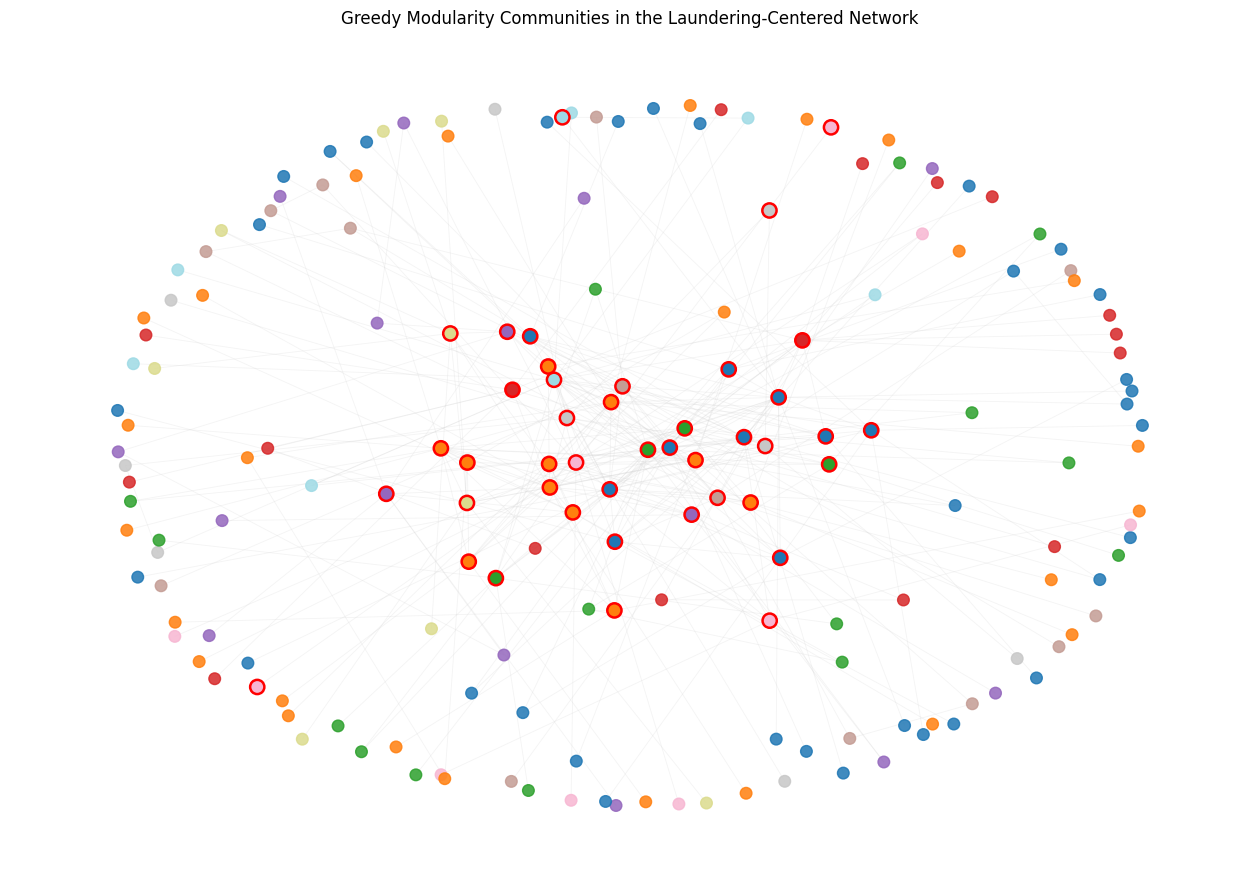

In [ ]:
# 13. VISUALIZE COMMUNITIES

node_community = [
    community_map[node]
    for node in G_undirected.nodes()
]

seed_nodes_plot = [
    node
    for node in G_undirected.nodes()
    if G_undirected.nodes[node][
        "is_laundering_seed"
    ] == 1
]

pos = nx.spring_layout(
    G_undirected,
    seed=42,
    k=1.2,
    iterations=100
)

plt.figure(figsize=(16, 11))

# Relationships
nx.draw_networkx_edges(
    G_undirected,
    pos,
    edge_color="lightgray",
    alpha=0.25,
    width=0.6
)

# Nodes colored according to community
nx.draw_networkx_nodes(
    G_undirected,
    pos,
    node_color=node_community,
    cmap=plt.cm.tab20,
    node_size=70,
    alpha=0.85
)

# Laundering seeds get a red outline
nx.draw_networkx_nodes(
    G_undirected,
    pos,
    nodelist=seed_nodes_plot,
    node_color=[
        community_map[node]
        for node in seed_nodes_plot
    ],
    cmap=plt.cm.tab20,
    node_size=105,
    edgecolors="red",
    linewidths=1.8
)

plt.title(
    "Greedy Modularity Communities in the Laundering-Centered Network"
)

plt.axis("off")
plt.show()

In [ ]:
# COMMUNITY-SEPARATED LAYOUT

import math

# Number of detected communities
n_communities = len(commlist)

# Arrange community centers in a grid
n_cols = math.ceil(math.sqrt(n_communities))

community_pos = {}

for community_id, community in enumerate(
    commlist,
    start=1
):

    # Create subgraph for this community
    H = G_undirected.subgraph(community)

    # Layout nodes INSIDE the community
    local_pos = nx.spring_layout(
        H,
        seed=42,
        scale=1
    )

    # Determine where this community sits in the overall plot
    row = (community_id - 1) // n_cols
    col = (community_id - 1) % n_cols

    x_offset = col * 4
    y_offset = -row * 4

    # Move the whole community to its assigned location
    for node, (x, y) in local_pos.items():
        community_pos[node] = (
            x + x_offset,
            y + y_offset
        )

## Visualization of identified communities

Within-community edges: 216
Between-community edges: 93


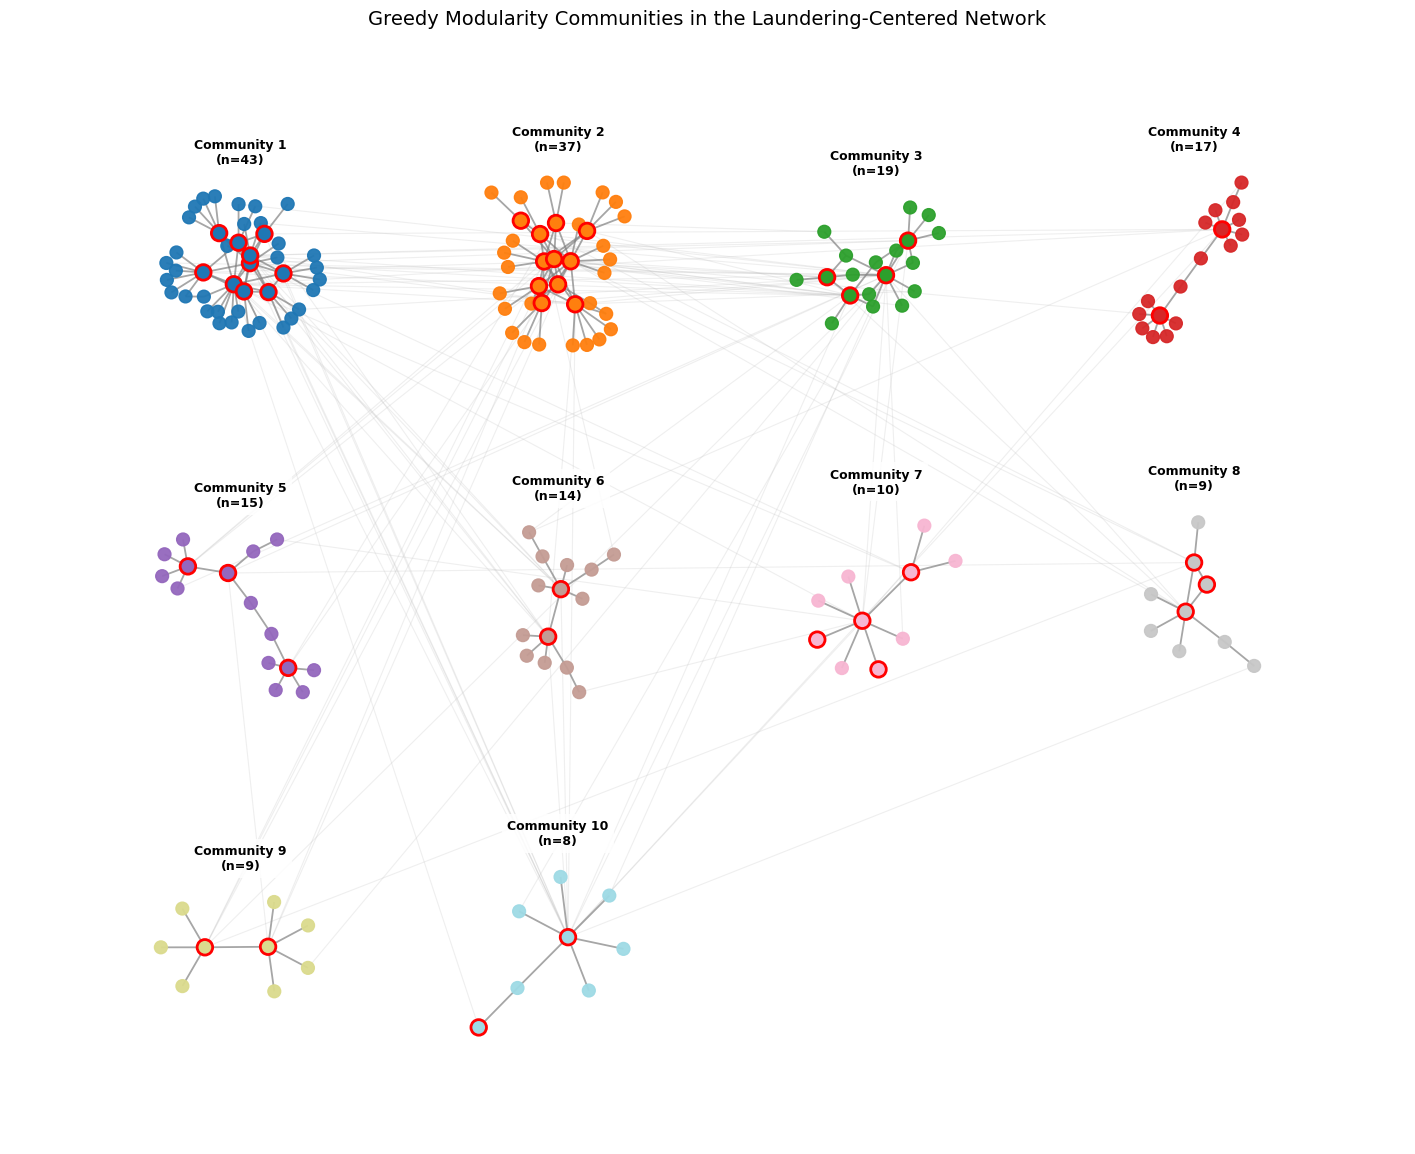

In [ ]:
# COMMUNITY-SEPARATED NETWORK PLOT

# Separate within- and between-community edges
within_edges = [
    (u, v) for u, v in G_undirected.edges()
    if community_map[u] == community_map[v]
]

between_edges = [
    (u, v) for u, v in G_undirected.edges()
    if community_map[u] != community_map[v]
]

print("Within-community edges:", len(within_edges))
print("Between-community edges:", len(between_edges))

# Node information
node_community = [
    community_map[n]
    for n in G_undirected.nodes()
]

seed_nodes_plot = [
    n for n in G_undirected.nodes()
    if G_undirected.nodes[n].get(
        "is_laundering_seed", 0
    ) == 1
]

plt.figure(figsize=(18, 14))

# Edges
nx.draw_networkx_edges(
    G_undirected,
    community_pos,
    edgelist=between_edges,
    edge_color="silver",
    alpha=0.25,
    width=0.8
)

nx.draw_networkx_edges(
    G_undirected,
    community_pos,
    edgelist=within_edges,
    edge_color="gray",
    alpha=0.70,
    width=1.3
)

# All nodes
nx.draw_networkx_nodes(
    G_undirected,
    community_pos,
    node_color=node_community,
    cmap=plt.cm.tab20,
    node_size=85,
    alpha=0.95
)

# Laundering seeds with red borders
nx.draw_networkx_nodes(
    G_undirected,
    community_pos,
    nodelist=seed_nodes_plot,
    node_color=[
        community_map[n]
        for n in seed_nodes_plot
    ],
    cmap=plt.cm.tab20,
    node_size=125,
    edgecolors="red",
    linewidths=2
)

# Community labels
for community_id, community in enumerate(
    commlist,
    start=1
):
    nodes = list(community)

    x = np.mean([
        community_pos[n][0]
        for n in nodes
    ])

    y = max(
        community_pos[n][1]
        for n in nodes
    ) + 0.35

    plt.text(
        x,
        y,
        f"Community {community_id}\n(n={len(nodes)})",
        ha="center",
        va="bottom",
        fontsize=9,
        fontweight="bold",
        bbox=dict(
            facecolor="white",
            alpha=0.85,
            edgecolor="none"
        )
    )

plt.title(
    "Greedy Modularity Communities in the Laundering-Centered Network",
    fontsize=14,
    pad=30
)

plt.axis("off")
plt.margins(0.08)
plt.show()

## Community-level characteristics

In [ ]:
# COMMUNITY-LEVEL CHARACTERISTICS

community_rows = []

for community_id, community in enumerate(commlist, start=1):

    nodes = set(community)
    H = G_undirected.subgraph(nodes)

    # Basic counts
    community_size = H.number_of_nodes()
    internal_edges = H.number_of_edges()

    # Laundering characteristics
    n_seeds = sum(
        G_undirected.nodes[n].get("is_laundering_seed", 0)
        for n in nodes
    )

    n_laundering_edges = sum(
        d.get("is_laundering", 0)
        for _, _, d in H.edges(data=True)
    )

    # Structural characteristics
    degrees = dict(H.degree())
    top_node = max(degrees, key=degrees.get) if degrees else None

    # Store results
    community_rows.append({
        "community": community_id,
        "community_size": community_size,
        "internal_edges": internal_edges,

        "laundering_seeds": n_seeds,
        "pct_laundering_seeds":
            100 * n_seeds / community_size if community_size else 0,

        "laundering_edges": n_laundering_edges,
        "pct_laundering_edges":
            100 * n_laundering_edges / internal_edges if internal_edges else 0,

        "density": nx.density(H),

        "avg_degree":
            np.mean(list(degrees.values())) if degrees else 0,

        "avg_clustering":
            nx.average_clustering(H) if community_size > 1 else 0,

        "cross_community_edges": sum(
            1
            for n in nodes
            for neighbor in G_undirected.neighbors(n)
            if neighbor not in nodes
        ),

        "total_transactions": sum(
            d.get("n_tx", 1)
            for _, _, d in H.edges(data=True)
        ),

        "top_node": top_node,

        "max_degree":
            degrees[top_node] if top_node else 0,

        "top_node_is_seed":
            G_undirected.nodes[top_node].get(
                "is_laundering_seed", 0
            ) if top_node else 0
    })


community_summary_df = pd.DataFrame(community_rows)

community_summary_df

,community,community_size,internal_edges,laundering_seeds,pct_laundering_seeds,laundering_edges,pct_laundering_edges,density,avg_degree,avg_clustering,cross_community_edges,total_transactions,top_node,max_degree,top_node_is_seed
0,1,43,61,10,23.255814,26,42.622951,0.067553,2.837209,0.064646,37,383,121_8000E1590,14,1
1,2,37,55,11,29.729730,26,47.272727,0.082583,2.972973,0.097483,34,289,48308_811ED7DF0,13,1
2,3,19,24,4,21.052632,1,4.166667,0.140351,2.526316,0.113200,38,240,70_100428A08,9,1
3,4,17,16,2,11.764706,0,0.000000,0.117647,1.882353,0.000000,7,193,119_8000DA7D0,7,1
4,5,15,14,3,20.000000,1,7.142857,0.133333,1.866667,0.000000,10,150,149345_812D1AC00,5,1
5,6,14,13,2,14.285714,1,7.692308,0.142857,1.857143,0.000000,15,157,119_811DCA9B0,6,1
6,7,10,9,4,40.000000,0,0.000000,0.200000,1.800000,0.000000,10,121,223_811A00890,7,1
7,8,9,9,3,33.333333,2,22.222222,0.250000,2.000000,0.155556,9,74,148016_811FCA7B0,6,1
8,9,9,8,2,22.222222,1,12.500000,0.222222,1.777778,0.000000,9,75,249176_81235EC40,5,1
9,10,8,7,2,25.000000,0,0.000000,0.250000,1.750000,0.000000,17,81,223_811A4DBD0,6,1


The communities most strongly exhibiting laundering are characterized by the co-occurrence of multiple laundering-seed accounts and a high proportion of laundering-labeled internal relationships. Communities 1 and 2 demonstrate this most clearly, indicating that known laundering activity is embedded within their internal network structure. However, the results also show that laundering can manifest differently: Community 7 has a high concentration of laundering-related accounts but no internal laundering edges, suggesting that its laundering activity occurs across community boundaries. Thus, laundering-related network structure cannot be identified using a single feature such as density, transaction volume, or seed concentration; rather, the combination of node-level laundering status, edge-level laundering activity, internal connectivity, and cross-community relationships provides a more informative picture. Thus, in this component, no single feature such as density, transaction volume, or seed concentration identifies the laundering-heavy communities (Communities 1 and 2 are actually less dense than most others); the combination of node-level laundering status, edge-level laundering activity, internal connectivity, and cross-community relationships is more informative. These are descriptive observations across 10 communities and were not statistically tested.

In [ ]:
# 14. TOP COMMUNITIES BY SIZE

print("Top communities by size:\n")

for idx, community in enumerate(
    commlist[:10],
    start=1
):

    print(
        "Community:",
        idx,
        "| Size:",
        len(community)
    )

Top communities by size:

Community: 1 | Size: 43
Community: 2 | Size: 37
Community: 3 | Size: 19
Community: 4 | Size: 17
Community: 5 | Size: 15
Community: 6 | Size: 14
Community: 7 | Size: 10
Community: 8 | Size: 9
Community: 9 | Size: 9
Community: 10 | Size: 8


In [ ]:
# 15. COMMUNITY SUMMARY

community_summary = []

for community_id, community in enumerate(
    commlist,
    start=1
):

    nodes = set(community)

    H = G_undirected.subgraph(nodes)

    n_nodes = H.number_of_nodes()

    n_edges = H.number_of_edges()

    n_seeds = sum(
        H.nodes[node]["is_laundering_seed"]
        for node in H.nodes()
    )

    laundering_edges = sum(
        data.get("is_laundering", 0)
        for _, _, data
        in H.edges(data=True)
    )

    community_summary.append({
        "community": community_id,
        "total_nodes": n_nodes,
        "total_edges": n_edges,
        "laundering_seed_nodes": n_seeds,
        "seed_rate": n_seeds / n_nodes,
        "laundering_edges": laundering_edges
    })


community_summary_df = pd.DataFrame(
    community_summary
)

community_summary_df.sort_values(
    "seed_rate",
    ascending=False
).head(10)

,community,total_nodes,total_edges,laundering_seed_nodes,seed_rate,laundering_edges
6,7,10,9,4,0.400000,0
7,8,9,9,3,0.333333,2
1,2,37,55,11,0.297297,26
9,10,8,7,2,0.250000,0
0,1,43,61,10,0.232558,26
8,9,9,8,2,0.222222,1
2,3,19,24,4,0.210526,1
4,5,15,14,3,0.200000,1
5,6,14,13,2,0.142857,1
3,4,17,16,2,0.117647,0


In [ ]:
# 16. SELECT AN INTERESTING COMMUNITY

eligible_communities = community_summary_df[
    community_summary_df["total_nodes"] >= 5
]

selected_community_id = int(
    eligible_communities
    .sort_values(
        [
            "seed_rate",
            "laundering_seed_nodes"
        ],
        ascending=False
    )
    .iloc[0]["community"]
)

print(
    "Selected community:",
    selected_community_id
)

selected_nodes = {
    node
    for node, community_id
    in community_map.items()
    if community_id == selected_community_id
}

comm1 = G_undirected.subgraph(
    selected_nodes
).copy()

print(
    f"Community {selected_community_id}: "
    f"{comm1.number_of_nodes()} nodes, "
    f"{comm1.number_of_edges()} edges"
)

Selected community: 7
Community 7: 10 nodes, 9 edges


## Visualize selected community
Visualization of the selected laundering-centered subnetwork revealed hub-and-spoke structures, where one highly connected account acts as a central hub linked to several less-connected counterparties, as well as repeated relationships and connections among laundering-seed accounts. In Community 7, the seed account 223_811A00890 serves as such a hub. All seven of its relationships inside the community are unlabeled and involve repeated transactions (14–21 each). Its laundering-labeled relationships are all with accounts outside the community: three single-transaction links to seed accounts in Communities 1, 3 and 10 (see the table below). This is consistent with Community 7's laundering activity occurring across community boundaries, and the hub's links to these other laundering-active communities may warrant further inspection.

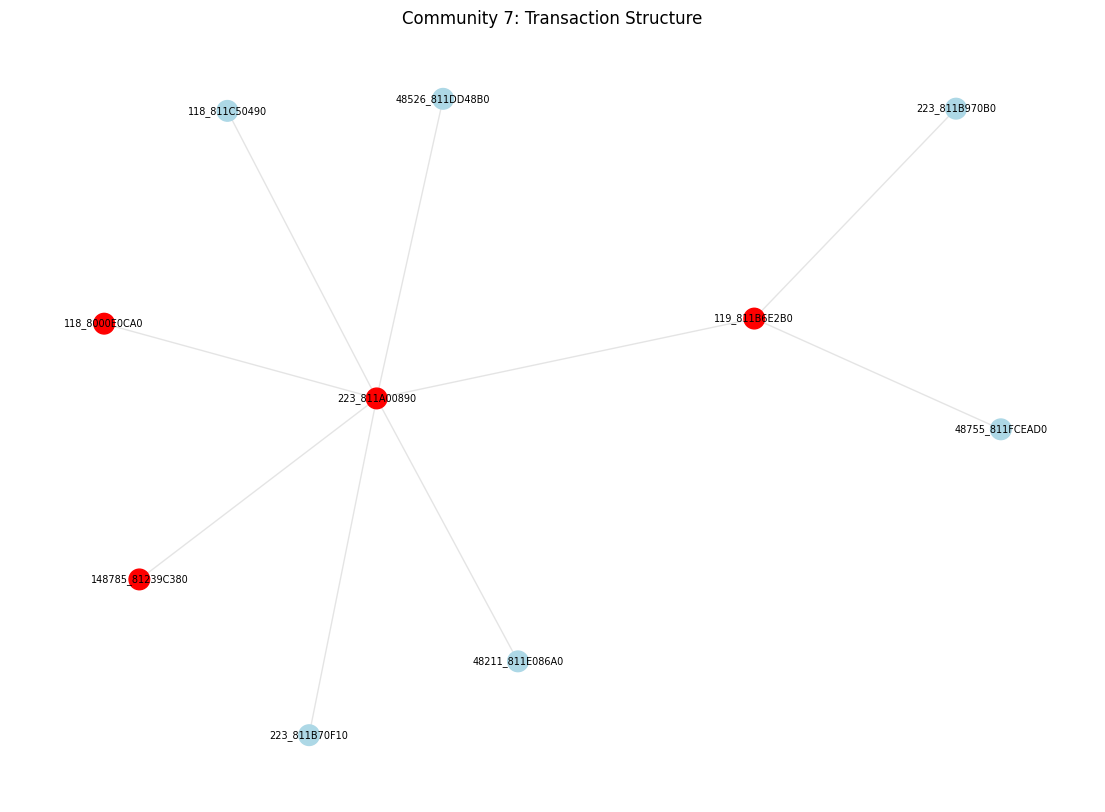

In [ ]:
# 17. VISUALIZE SELECTED COMMUNITY

pos = nx.spring_layout(
    comm1,
    seed=42
)

node_colors = [
    "red"
    if comm1.nodes[node][
        "is_laundering_seed"
    ] == 1
    else "lightblue"
    for node in comm1.nodes()
]

edge_colors = [
    "red"
    if data.get(
        "is_laundering", 0
    ) == 1
    else "lightgray"
    for _, _, data
    in comm1.edges(data=True)
]

plt.figure(figsize=(14, 10))

nx.draw_networkx_edges(
    comm1,
    pos,
    edge_color=edge_colors,
    alpha=0.6
)

nx.draw_networkx_nodes(
    comm1,
    pos,
    node_color=node_colors,
    node_size=220
)

nx.draw_networkx_labels(
    comm1,
    pos,
    font_size=7
)

plt.title(
    f"Community {selected_community_id}: "
    "Transaction Structure"
)

plt.axis("off")
plt.show()

In [ ]:

# SELECT SUBJECT ACCOUNT

community_seed_nodes = [
    node
    for node in comm1.nodes()
    if comm1.nodes[node][
        "is_laundering_seed"
    ] == 1
]

subject_node = max(
    community_seed_nodes,
    key=comm1.degree
)

print(
    "Selected account for inspection:",
    subject_node
)

Selected account for inspection: 223_811A00890


In [ ]:
# Inspect its attributes
comm1.nodes[
    subject_node
]

# Inspect its degree
print(
    "Degree:",
    comm1.degree(subject_node)
)

# Inspect its counterparties
list(
    comm1.edges(
        subject_node
    )
)

# Inspect one relationship
example_edge = list(
    comm1.edges(
        subject_node
    )
)[0]

print(
    "Example relationship:",
    example_edge
)

u, v = example_edge

comm1.get_edge_data(
    u,
    v
)



Degree: 7
Example relationship: ('223_811A00890', '118_811C50490')


{'n_tx': 20, 'total_amount': 815717.4, 'n_laundering': 0, 'is_laundering': 0}

In [ ]:

# COUNTERPARTY TABLE


counterparty_records = []

for u, v, data in comm1.edges(
    subject_node,
    data=True
):

    counterparty = (
        v if u == subject_node else u
    )

    counterparty_records.append({
        "subject": subject_node,
        "counterparty": counterparty,

        "counterparty_is_seed":
            comm1.nodes[counterparty][
                "is_laundering_seed"
            ],

        "n_tx":
            data.get("n_tx"),

        "total_amount":
            data.get("total_amount"),

        "n_laundering":
            data.get("n_laundering"),

        "is_laundering":
            data.get("is_laundering")
    })


counterparty_df = pd.DataFrame(
    counterparty_records
)

counterparty_df.sort_values(
    [
        "is_laundering",
        "n_laundering"
    ],
    ascending=False
)

,subject,counterparty,counterparty_is_seed,n_tx,total_amount,n_laundering,is_laundering
0,223_811A00890,118_811C50490,0,20,815717.40,0,0
1,223_811A00890,223_811B70F10,0,1,224225.07,0,0
2,223_811A00890,118_8000E0CA0,1,21,2862333.11,0,0
3,223_811A00890,48526_811DD48B0,0,14,106698.13,0,0
4,223_811A00890,119_811B6E2B0,1,7,163591.54,0,0
5,223_811A00890,148785_81239C380,1,21,48211571.73,0,0
6,223_811A00890,48211_811E086A0,0,20,43292.40,0,0


**Relationships of the hub outside Community 7.** The table above shows only the hub's relationships inside the community. The table below shows the rest.

In [ ]:
# The hub's relationships outside Community 7 (comm1 only contains internal edges)
pd.DataFrame([
    {"counterparty": nb,
     "community": G_undirected.nodes[nb]["community"],
     "counterparty_is_seed": G_undirected.nodes[nb]["is_laundering_seed"],
     "n_tx": d["n_tx"], "n_laundering": d["n_laundering"], "is_laundering": d["is_laundering"]}
    for nb, d in G_undirected[subject_node].items() if nb not in comm1
]).sort_values("is_laundering", ascending=False)

,counterparty,community,counterparty_is_seed,n_tx,n_laundering,is_laundering
0,121_8000E1590,1,1,1,1,1
5,223_811A4DBD0,10,1,1,1,1
3,119_811B88600,3,1,1,1,1
2,48308_811C5A680,5,0,1,0,0
1,121_811A64E70,6,0,50,0,0
4,121_811A4C0D0,4,0,1,0,0
6,70_100428A08,3,1,14,0,0


**Community-Level Findings**

Greedy Modularity Maximization identified 10 distinct communities within this laundering-centered component. The communities vary considerably in size, connectivity, and concentration of laundering-related activity.

Communities 1 and 2 emerged as the most prominent laundering-associated groups. Community 1 contains 43 accounts, including 10 laundering seed accounts, with 26 of its 61 internal relationships (42.62%) involving at least one laundering-labeled transaction. Community 2 contains 37 accounts and 11 laundering seed accounts, while 26 of its 55 internal relationships (47.27%) are laundering-labeled.

These findings indicate that known laundering activity is not distributed evenly across the network. Instead, some communities contain substantially greater concentrations of laundering-related accounts and relationships, making them stronger candidates for further inspection.

# Key Findings and Answers to the Objectives

**1. Describe the network in terms of nodes, edges, degree patterns, density, and connectedness.**

The laundering-centered subgraph has 64,067 accounts and 82,238 edges (out of 422,734 accounts and 647,939 relationships in the full network). The average degree is only 1.28. At least half of the accounts only receive money, and two accounts (70_100428660 and 70_1004286A8) send to 14,230 and 8,846 accounts, which together account for 28% ((14,230 + 8,846) / 82,238) of all relationships. The network is extremely sparse, with a network density of about 2.00e-05. It is almost one connected piece in the weak sense: 147 weakly connected components exist, but one giant component holds 62,459 accounts (97.5%). It is very fragmented in the strong sense: there are 63,269 strongly connected components for 64,067 accounts, so money mostly flows in one direction.


**2. Compare the network characteristics of laundering seed accounts and neighboring non-seed accounts.**

Seed accounts and their one-hop non-seed neighbors look structurally similar. Medians match for degree (3 counterparties), clustering (0) and ego density (0.5), and triangles are near zero in both groups (AUC 0.46), so no single neighborhood measure separates them. Seeds have slightly fewer counterparties (middle half roughly 1–4 versus 2–5), partly because neighbors are in the sample only because they touch a seed and the seeds' laundering edges were removed from the comparison graph. Clustering differs only at degrees 2–3, and the gap closes above that. The relational-neighbor feature and the combined model's AUC (0.874) mostly reflect how the samples were built, so they are not evidence that neighborhood structure detects laundering. Local structure alone therefore does not distinguish seeds, laundering concentration is clearer at the community level (objective 5).

**3. Identify highly connected or structurally important accounts using network centrality measures.**

A few accounts dominate.
Degree, in-degree, out-degree, PageRank and betweenness (approximated from sampled source nodes) all rank the same two bank-70 accounts first: 70_100428660 (degree centrality 0.23, sending to about 22% of all accounts) and 70_1004286A8 (about 13.8%). Closeness also ranks 70_100428660 first, but the runner-up is a different account (5394_806A65C90), and the top ten values are tightly packed (0.0058–0.0085), so closeness separates accounts poorly here.
All ten of the highest fan-out accounts belong to bank 70. Eigenvector centrality points to a different set of accounts (222_811D80C30, 118_811B6E170, 119_8000DB3C0, etc.).

**4. Examine transaction relationships involving laundering-related accounts.**

The 5,166 laundering transactions aggregate into 4,929 sender–receiver relationships, 5.99% of the 82,238 edges in the laundering-centered network. Laundering relationships are less repeated than normal ones (median 1 transaction versus 6), typically somewhat smaller but with a heavier tail of very large amounts, and they account for a larger share of their sender's outgoing money (median 0.15 versus about 0). By payment format, laundering transactions are concentrated in ACH (86.6% versus 11.7% of normal transactions), although fewer than 1% of ACH transactions are laundering-labeled.

**5. Detect network communities and determine how laundering activity is distributed across them.**

Community detection identified distinct groups in which laundering activity was unevenly distributed, with Communities 1 and 2 showing the strongest internal concentration of laundering-labeled relationships. Other communities, such as Community 7, contained a high proportion of laundering-seed accounts but no internal laundering-labeled edges, indicating that laundering activity may also extend across community boundaries.
*Scope note: community detection was run on one laundering-centered component (a 39-account laundering core expanded one hop to 181 accounts and 309 relationships; the eligible component with the largest expanded size among 164 candidates of 30–300 accounts), not on the full 64,067-account network. Findings describe that component and may not generalize.*

**6. Visualize selected laundering-centered subnetworks to identify relationships that may warrant further inspection.**

Visualization of the selected laundering-centered subnetwork revealed hub-and-spoke structures, where one highly connected account acts as a central hub linked to several less-connected counterparties, as well as repeated relationships and connections among laundering-seed accounts. In Community 7, the seed account 223_811A00890 serves as such a hub. All seven of its relationships inside the community are unlabeled and involve repeated transactions (14–21 each). Its laundering-labeled relationships are all with accounts outside the community: three single-transaction links to seed accounts in Communities 1, 3 and 10 (see the hub table in the community section). This is consistent with Community 7's laundering activity occurring across community boundaries, and the hub's links to these other laundering-active communities may warrant further inspection.

# Lesson Synthesis
- How can you use graph metrics such as density, transitivity, and diameter in analyzing fraud?
- How does knowing which nodes have high degrees, eigvenvector, betweenness, and closeness measures help in analyzing importance of a node?
- How does visualization help in graph analysis?
- How do you compare the pros and cons of using graph and non-graph analysis?
- Besides fraud, what other ways can social network analysis be beneficial as a form of analysis?

# References
- Graph Theory Lectures https://medium.com/basecs/a-gentle-introduction-to-graph-theory-77969829ead8
- Introduction to networkx https://medium.com/analytics-vidhya/a-gentle-introduction-to-networkx-with-python-21c29419d28a
- scikit-network: Alternative graph libary https://scikit-network.readthedocs.io/en/latest/|